 Copyright © Sorbonne University.

 This source code is licensed under the MIT license found in the
 LICENSE file in the root directory of this source tree.

# Authors: Asmaa Jamai

# GitHub repository: https://github.com/asmaa-jamai/APCO-TP1-Asmaa-Jamai.git

# Outlook

In this notebook, we study basic linear and non-linear regression algorithms.
Regression is another name for function approximation, it consists in fitting a function to a set of points, as shown below.

The notebook is meant to study elements presented in lessons available in video here 
https://www.youtube.com/playlist?list=PLe5mY-Da-ksURGcelU-egwtWZXxVgZ76a

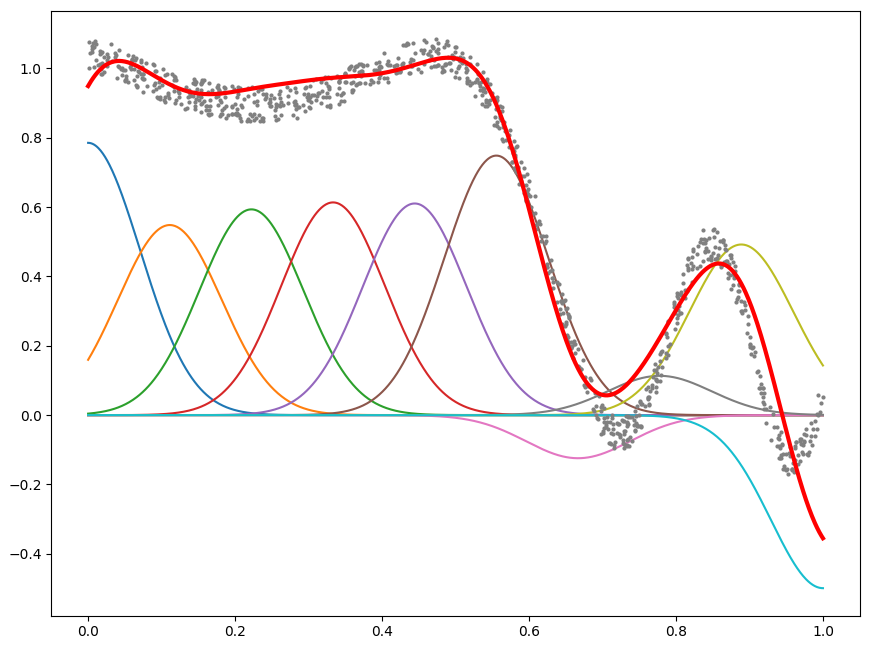


The notebook contains coding parts, where you have to code the main regression algorithms and check they work with a visualization,
and study parts, where you investigate their properties when changing some parameters or where you perform comparisons between methods. 
The study part may involve further coding to generate appropriate diagrams.

There are more studies than doable in a short time.
Do what you can among the studies. 
Doing one study accurately is better than being inaccurate on all studies.


# Installation

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

# %pip install -q git+https://github.com/osigaud/regressionLabs

from regression_labs.batch import Batch
from regression_labs.latent_function import LinearLatentFunction, NonLinearLatentFunction, NonLinearLatentXDFunction
from regression_labs.gaussians import Gaussians

# Introduction

The objective of regression or function approximation is to create a model from observed data. 
The model has a fixed structure with parameters (like the coefficients of a polynomial for instance), 
and regression consists in adjusting these parameters to fit the data. 
In machine learning, it is a very important technique since having a good model enables better predictions and performance.

With mathematical notations, given some datapoints $\{ ({\bf x}, {\bf y}) \}$, 
the goal is to adjust a model ${\bf y} = f({\bf x})$ so that the *learned* function $f$ accounts for these datapoints 
and generalize well to other unseen points $\{ ({\bf x}, {\bf y}) \}$.

The simplest case is linear regression, which assumes a relation of type ${\bf y} = {\bf A}{\bf x} + {\bf b}$ 
between the data ${\bf x}$ and ${\bf y}$.

Several methods exist to adjust the parameters ${\bf A}$ and ${\bf b}$, 
the most well-known being the least squares method (or least norm in the multivariate case).

In this lab, we assume that ${\bf y}$  is of dimension 1 (and write $y$ instead of ${\bf y}$  in what follows). 
This is a very common assumption.

Furthermore, in the code ${\bf x}$ is also of dimension 1, this is more restrictive 
as regression is often used from multidimensional input data.

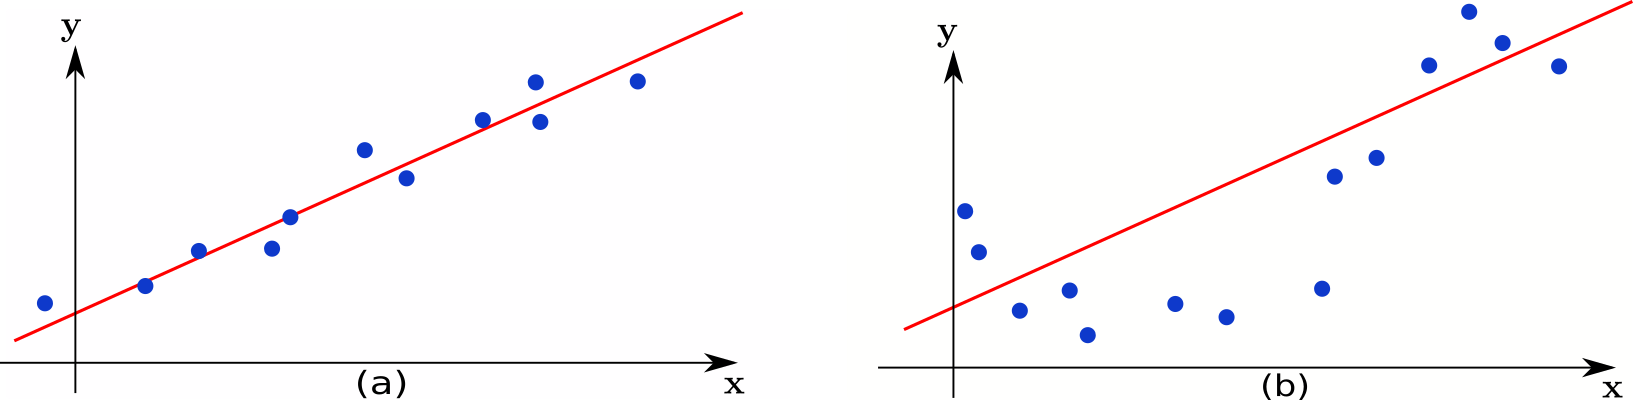


Often, linear models are not enough. For instance, see figures (a) and (b) above, 
on the left a linear regression is OK, but on the right it is not. 
In the case of (b), we must rely on nonlinear models. 
Here, we focus on the case where $f$ can be written as a sum of $k$ functions parametrized by vectors ${\boldsymbol{\theta}}_i$:

$$ f({\bf x})  = \sum_{i=1}^k f_{\boldsymbol{\theta}_i}({\bf x}).$$

In particular, we use Gaussian functions.

## Weighted sums of Gaussian functions

Gaussian functions $\phi_i({\bf x}) = \exp(-\frac{({\bf x}-{\bf c_i})^2}{\sigma_i^2})$ are almost equal to zero 
everywhere except in a neighborhood of ${\bf c_i}$, which represents the "center"' of the Gaussian (see the figure below). 
The value of $\sigma_i$ determines how large this neighborhood is.

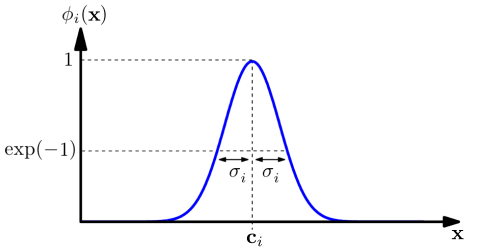

Then weighted Gaussian functions $f_{\boldsymbol{\theta}_i}$ can be written:

$$ f_{\boldsymbol{\theta}_i} = {\bf \theta}_i \phi_i({\bf x}) = {\bf \theta}_i \exp\left(-\frac{({\bf x}-{\bf c_i})^2}{\sigma_i^2}\right). $$

In RBFNs, the centers of the Gaussian functions are fixed in advance, and evenly distributed in the input space. 
Besides, all the $\sigma_i$'s are usually set to the same value.
Thus weighted Gaussian functions $f_{\boldsymbol{\theta}_i}$ have a unique scalar parameter 
which is their vector of weights $\boldsymbol{\theta}_i$.

# Provided code and documentation

The numpy reference guide is here: http://docs.scipy.org/doc/numpy/reference/

We provide a few useful classes and the infrastructure to perform these labs.

## Data generation

Two functions to generate points corresponding to a noisy linear and a noisy nonlinear model are provided in 
the ```LatentFunction``` class in the 
[latent_function.py](https://github.com/osigaud/regressionLabs/blob/main/regression_labs/latent_function.py) file.

## Batch of data

The [batch.py](https://github.com/osigaud/regressionLabs/blob/main/regression_labs/batch.py) file contains 
the ```Batch``` class. This class is used to collect a batch of linear or non-linear data, either in a single batch or incrementally.

## Vectors of Gaussian functions

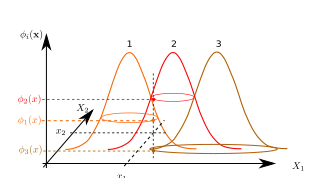

A ```Gaussians``` class is provided in [gaussians.py](https://github.com/osigaud/regressionLabs/blob/main/regression_labs/gaussians.py) 
to represent a vector of Gaussian feature functions $\phi({\bf x})$ of an input vector ${\bf x}$, 
as used in RBFNs and Locally Weighted Regression (LWR) (see below). 
The number $E$ of elements of $\phi({\bf x})$ (i.e. the number $E$ of Gaussian functions) is defined by the ```nb_features``` attribute. 

Given some input vector ${\bf x}$, the function ```phi_output(x)``` returns 
the vector of the output of (non-weighted) Gaussian functions applied to ${\bf x}$, thus a vector of size $E$.
In the particular case where $x$ is a scalar, it is transformed into a one element vector to keep consistent with the N-dimensional case.

Note that the input of the (multivariate) Gaussian functions is of the same dimension as ${\bf x}$, 
but their output is one-dimensional (see the figure above).

## Function approximators

We consider three families of approximation models: linear models , radial basis function networks and locally weigthed regression models. 
In all these models, the theta attribute represents the vector of parameters to be optimized. 
The ```f(self, x)``` function represents the function approximator output for a given input ```x```, to be optimized. 
The parameters used by $f$ are the elements of the ```theta``` vector.

For instance, for RBFNs, we consider a vector of $E$ Gaussian functions 
$\phi({\bf x}) = (\phi_1({\bf x}) \ \phi_2({\bf x}) \cdots \phi_E({\bf x}))^\intercal$, 
a vector of weights $\boldsymbol{\theta} = (\boldsymbol{\theta}_1 \ \boldsymbol{\theta}_2 \cdots \boldsymbol{\theta}_E)^\intercal$, 
and a vector of weighted Gaussian functions $f({\bf x}) = \phi({\bf x})^\intercal \boldsymbol{\theta}$.

These function approximation models come with various ```train_...(self, ...)``` functions that you must fill.

# Visualization

For all the regression methods described below, as illustrated in the figure at the top of this notebook, 
after executing it, the observed data are shown by points, and the red curve is the *learned* function $f$ 
corresponding to the parameters $\boldsymbol{\theta}$ that have been incrementally adjusted. 
When this applies, the other curves correspond to the $f_{\boldsymbol{\theta}_i}({\bf x})$ functions, 
they show the decomposition of $f$, which is the sum of all these functions. 
All visualization functions are in the ```plot()``` function of each approximator.

# Notations and code helpers

We consider either a batch regression approach, an iterative one or an incremental one. In the batch and iterative approaches, we consider a batch of data consisting of $N$ $\{ ({\bf x}_i, y_i) \}_{1 \leq i \leq N}$ pairs.
In the incremental one, we get an additional pair of data $({\bf x}^{(t)}, y^{(t)})$ at each time step $t$.

In the general case, an input datapoint ${\bf x}$ is of dimension $d$, and we have ${\bf x} = (x_1 \ x_2 \cdots x_d)^\intercal$.
Under algebraic form, the batch of data is rewritten $({\bf X}, {\bf y})$ where ${\bf X}$ is a $N \times d$ matrix and ${\bf y}$ is a $N$ dimensional vector.

## Issues with ```transpose()``` in numpy

In regression algorithms, we often use the transpose operator.
But in numpy, transposing a standard one-dimensional vector does not work as expected: the result of the tranpose operator is the same vector, which is quite unfortunate.

Below we define two functions to fix this issue.

In [2]:
import numpy as np

def horiz_to_verti(vec):
  return vec.reshape(-1, 1)

def verti_to_horiz(vec):
  return vec.reshape(-1)

And here is a small example about how to use it.

In [3]:
vec = np.zeros(3)
print(vec)
v2 = vec.transpose()
print ("incorrect transpose:", v2)
v3 = horiz_to_verti(vec)
print ("correct transpose:", v3)
v4 = verti_to_horiz(v3)

print ("transpose of the transpose:", v4)

[0. 0. 0.]
incorrect transpose: [0. 0. 0.]
correct transpose: [[0.]
 [0.]
 [0.]]
transpose of the transpose: [0. 0. 0.]


## Augmenting the design matrix with one dimension

To solve a linear least square problem, we want to use a model of the form $f_\boldsymbol{\theta}({\bf X}) = \boldsymbol{\theta}^\intercal{\bf X} + {\bf b}$.
To deal more elegantly with the intercept ${\bf b}$, we extend the vectors ${\bf x}$ with an additional dimension
using $\bar{\bf x}_i = (x_{i,1} \ x_{i,2} \cdots x_{i,d} \ 1)^\intercal$, and we redefine the augmented design matrix as

$$\bar{\bf X}=\left(
\begin{array}{ccccc}
 x_{1,1}&x_{1,2}&\cdots &x_{1,d} &1\\
 x_{2,1}&x_{2,2}&\cdots &x_{2,d} &1\\
 \vdots  &\vdots  &\ddots &\vdots   &\vdots\\
 x_{N,1}&x_{N,2}&\cdots &x_{N,d} &1\\
\end{array}
\right).
$$

This way, our model can be rewritten $f_\boldsymbol{\theta}({\bf X}) = \boldsymbol{\theta'}^\intercal{\bar{\bf X}}$.

From the list of vectors *x_data* provided by the sample generator, $\bar{\bf X}$ can be obtained by first transforming *x_data* into a *numpy array* and transposing using

```x_data = numpy.array(x_data).transpose()```,

and then adding the ones with:

```barX = np.hstack((x_data, numpy.ones((x_data.shape[0], 1))))```

Let us define the ```bar_design()``` function

In [4]:
def bar_design(x):
  return np.hstack((x, np.ones((x.shape[0], 1))))

And check that it works.

In [5]:
lf = LinearLatentFunction()
batch = lf.get_batch(5)
barX = bar_design(batch.x_data)
print ("input:", batch.x_data)
print ("Augmented design matrix:", barX)

input: [[0.63896905]
 [0.16025396]
 [0.18177121]
 [0.98694338]
 [0.60300245]]
Augmented design matrix: [[0.63896905 1.        ]
 [0.16025396 1.        ]
 [0.18177121 1.        ]
 [0.98694338 1.        ]
 [0.60300245 1.        ]]


# Coding and study of regression algorithms

We now investigate four families of regression algorithms: 
- the Linear Least Squares (LLS),  
- Radial Basis Function Networks (RBFNs) using various fitting algorithms, 
- regression with neural networks,
- Locally Weighted Regression (LWR).

# Linear Least squares

## Coding part

### Batch Linear Least squares

The linear least squares method finds the best linear model from a batch of data, using

$$  \boldsymbol{\theta}^* = \min_{\boldsymbol{\theta}} \underbrace{\|{\bf y}-\boldsymbol{\theta}^\intercal\bar{\bf X}\|^2}_{L(\boldsymbol{\theta})}.$$

The parameters for the optimal model are given by:

$$ \boldsymbol{\theta}^* = (\bar{\bf X}^\intercal\bar{\bf X})^{-1}{\bar{\bf X}}^\intercal{\bf y}.$$

The code below provides the ```Line``` class. The way to get the linear least square model using *stats.linregress(x_data, y_data)* is given in the ```train_from_stats(self, x_data, y_data)``` function. In this provided function, **you just need to print the obtained values and set the ```self.theta``` attribute correctly**.

Then, fill the ```train(self, x_data, y_data)``` function so as to perform the same linear least square computation using the above equation, **without** using ```stats.linregress(x_data, y_data)```.

In [6]:
from scipy import stats

class LinearModel:
    def __init__(self, batch_size):
        self.nb_dims = 1
        # We add one to add the offset in the end of the vector
        self.theta = np.zeros(self.nb_dims + 1)

    def f(self, x):
        """
        Get the output of the function approximator for a given vector of input variables
        :param x: A single vector of input variables with size [Ns]
        :returns: the function approximator output
        """
        x_bar = bar_design(x)
        return np.dot(x_bar, self.theta)

    # -- compute the residuals --#
    def compute_error(self, x_data, y_data):
      error = np.linalg.norm(y_data-self.f(x_data))
      return error

    # ----------------------#
    ## Training Algorithms ##
    # ----------------------#

    def train_from_stats(self, x_data, y_data):
        # Finds the Least Square optimal weights: python provided version
        slope, intercept, r_value, _, _ = stats.linregress(verti_to_horiz(x_data), y_data)

        print("slope :", slope)
        print("intercept :", intercept)
        print("r_value :", r_value)


        self.theta = np.array([slope, intercept])
       


    def train(self, x_data, y_data):
        # Finds the Least Square optimal weights

        
        X = bar_design(x_data)                                                 #definisco la varibaile perche sarebbe X trattino, ma usiamo solo X per semplicità 
        self.theta = (np.linalg.inv(X.T@X)@X.T@y_data)
        


    def train_regularized(self, x_data, y_data, coef):
        # Finds the regularized Least Square optimal weights

    
        X = bar_design(x_data)
        
        self.theta = np.linalg.inv(coef * np.eye(2) + X.T @ X) @ X.T @ y_data           #i could also write np.eye(X.shape[1])
  


    # -----------------#
    # # Plot function ##
    # -----------------#

    def plot(self, x_data, y_data, title):
        xs = np.linspace(0.0, 1.0, 1000)
        z = []
        for i in xs:
            z.append(self.f(np.array([[i]])))

        plt.plot(x_data, y_data, 'o', markersize=3, color='lightgreen')
        plt.plot(xs, z, lw=2, color='red')
        plt.xlabel("x")
        plt.ylabel("y")
        plt.title(title)
        plt.show()

Visualize whether your code works.

theta: [3.12951045 0.13179779]
LLS time: 0.0016030000000002431


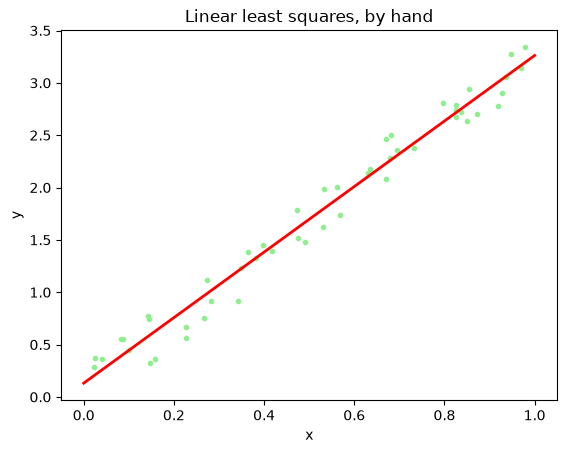

slope : 3.129510450635615
intercept : 0.13179778761014993
r_value : 0.9871248692498501
theta: [3.12951045 0.13179779]
LLS from scipy stats time: 0.0018400000000000638


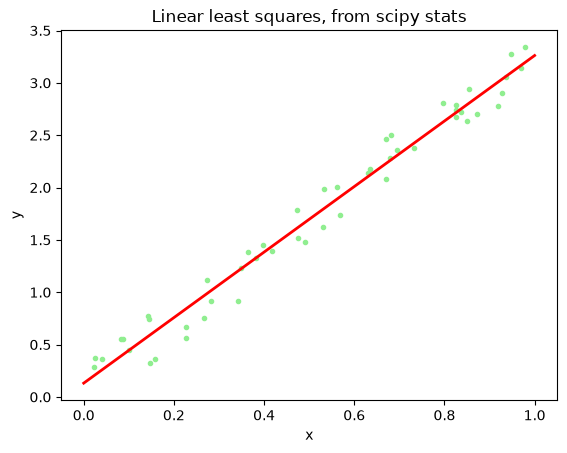

In [7]:
lf = LinearLatentFunction()
size = 50
batch = lf.get_batch(size)
model = LinearModel(size)

start = time.process_time()
x = np.array(batch.x_data)
y = np.array(batch.y_data)
model.train(x, y)
print("theta:", model.theta)
print("LLS time:", time.process_time() - start)
model.plot(x, y, "Linear least squares, by hand")

start = time.process_time()
model.train_from_stats(x, y)
print("theta:", model.theta)
print("LLS from scipy stats time:", time.process_time() - start)
model.plot(x, y, "Linear least squares, from scipy stats")

### Ridge Regression

The ridge regression (or regularized least squares, or Tikhonov regularization) method finds the best linear model from a batch of data, but ensuring that the obtained weights are not too high, using

$$ \boldsymbol{\theta}^* = \min_{\boldsymbol{\theta}} \underbrace{[\frac{\lambda}{2}||\boldsymbol{\theta}||^2 + \frac{1}{2}\|{\bf y}-\boldsymbol{\theta}^\intercal\bar{\bf X}\|^2]}_{L(\boldsymbol{\theta})}.$$

The parameters for the optimal model are given by:

$$ \boldsymbol{\theta}^* = (\lambda \boldsymbol{I} + \bar{\bf X}^\intercal\bar{\bf X})^{-1}{\bar{\bf X}}^\intercal{\bf y}.$$

In the Line class above, fill the `train_regularized(self, x_data, y_data, coef)` function.

And check that it works with a new batch of data

theta regularized: [3.12259696 0.13534796]
regularized LLS : 0.0019400000000002748


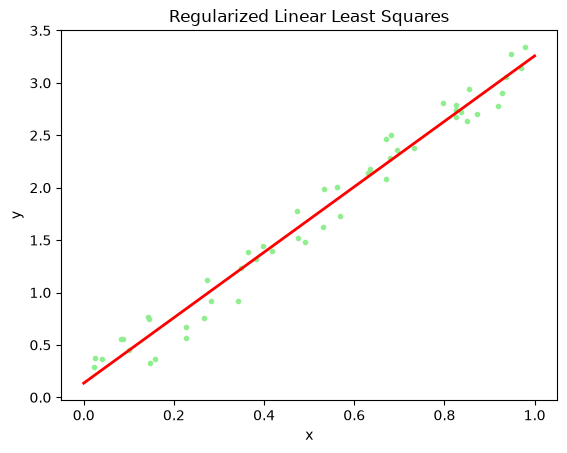

In [8]:
# We use the same batch as before, uncomment if you want to use another batch
# lf = LinearLatentFunction()
# size = 50
# batch = lf.get_batch(size)
model = LinearModel(size)

start = time.process_time()
model.train_regularized(batch.x_data, batch.y_data, coef=0.01)
print("theta regularized:", model.theta)
print("regularized LLS :", time.process_time() - start)
model.plot(batch.x_data, batch.y_data, "Regularized Linear Least Squares")

## Study part: linear least squares

### Key study: impact of regularization

For a batch of 50 points, study with the` train_regularized(self,x_data,y_data,coef)` function 
how the residuals degrade as you increase the value of ```coef``` in some well chosen range. 
Explain what you see. A good idea would be to make a picture with coef in the x axis and the residuals in the y axis, 
and then to comment it. Having a look at the learned model may also help.

### Optional study: comparing your LLS code and train_from_stats

Does your ```train(self, x_data, y_data)``` function provide exactly the same results 
as the ```train_from_stats(self, x_data, y_data)``` function?
Call both functions 1000 times with batches containing between 5000 and 50.000 data points and compare their run time with a figure.
Explain what you see.



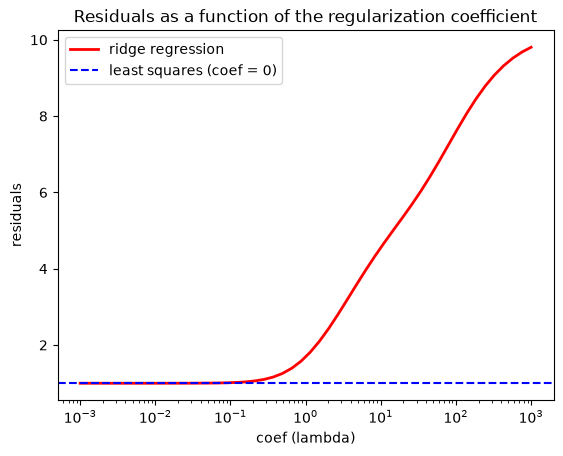

In [9]:
# Key study: impact of regularization (linear least squares)
# 1. Generate the data: one linear batch of 50 points, used for all the models
lf = LinearLatentFunction()
size = 50
batch = lf.get_batch(size)
x = np.array(batch.x_data)
y = np.array(batch.y_data)

# 2. Values of coef (lambda) to test: 50 values from 10^-3 to 10^3, log-spaced
coefs = np.logspace(-3, 3, 50)

# 3. For each coef: train a new model and store its residuals
errors = []
for coef in coefs:
    model = LinearModel(size)                      
    model.train_regularized(x, y, coef)           
    error = model.compute_error(x, y)             
    errors.append(error)                          

# 4. Reference: residuals of the non-regularized least squares (coef = 0)
model = LinearModel(size)
model.train(x, y)
error_lls = model.compute_error(x, y)

# 5. Plot residuals as a function of coef
plt.plot(coefs, errors, lw=2, color='red', label="ridge regression")
plt.axhline(error_lls, ls='--', color='blue', label="least squares (coef = 0)")
plt.xscale("log")                                  # log scale for coef
plt.xlabel("coef (lambda)")
plt.ylabel("residuals")
plt.title("Residuals as a function of the regularization coefficient")
plt.legend()
plt.show()



coef = 0.01  theta = [ 2.25528926 -2.45640595]  residuals = 0.997865042147577


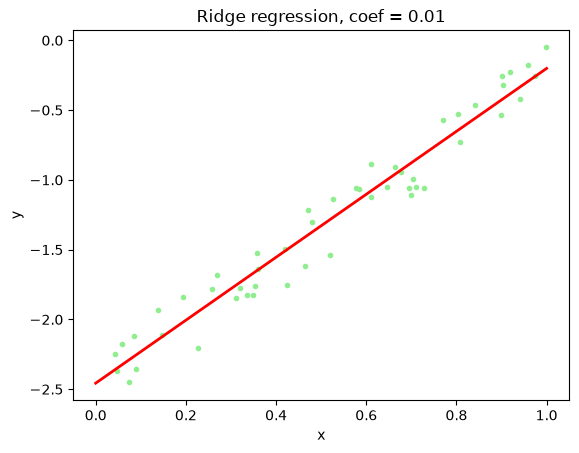

coef = 1  theta = [ 1.60748243 -2.07919804]  residuals = 1.6867834321860393


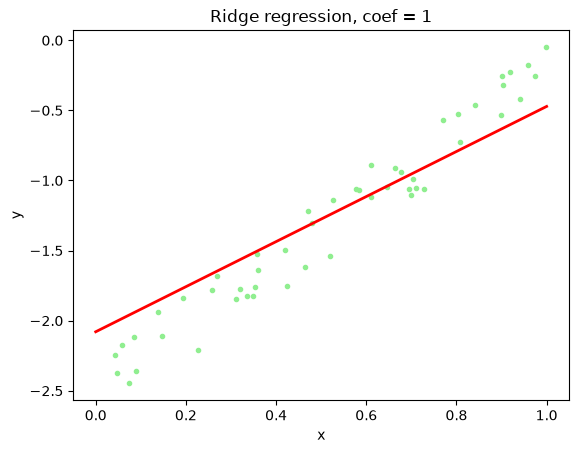

coef = 10  theta = [ 0.22655575 -1.170239  ]  residuals = 4.551979964328776


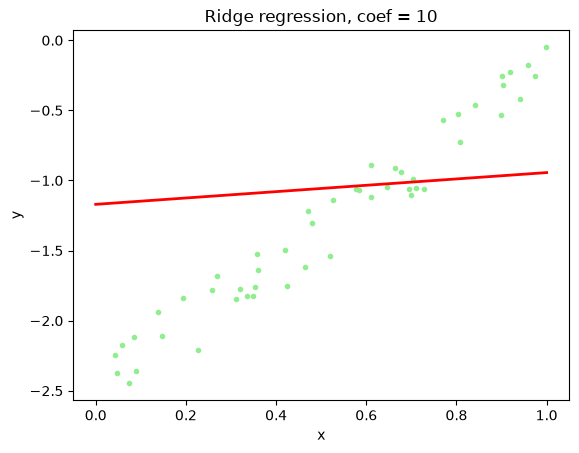

coef = 100  theta = [-0.11488626 -0.40904309]  residuals = 7.590479724594863


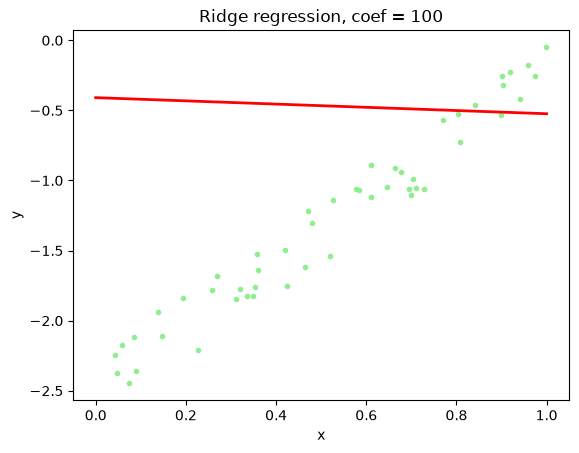

In [10]:
# 6. Look at the learned model for some values of coef (same batch as above)
for coef in [0.01, 1, 10, 100]:
    model = LinearModel(size)
    model.train_regularized(x, y, coef)
    print("coef =", coef, " theta =", model.theta, " residuals =", model.compute_error(x, y))
    model.plot(x, y, "Ridge regression, coef = " + str(coef))

## COMMENT:Key study: impact of regularization

For small values of coef the residuals are the same as with the non-regularized least squares: the penalty term is negligible compared to the data error, so the ridge solution is almost identical to the LLS one. For intermediate values of coef the residuals increase: the penalty becomes comparable to the data term, so the optimization trades fitting accuracy for smaller weights, and the slope is shrunk towards 0 (the line becomes flatter). For large values of coef the weights go to 0, the model tends to y = 0 and the residuals saturate towards the norm of y. On this problem regularization only degrades the fit, because a linear model with only 2 parameters cannot overfit 50 points. Ridge regression becomes useful with models having many parameters (e.g. RBFNs with many features), where it limits overfitting, and to make the matrix X̄ᵀX̄ always invertible.

5000 points | same theta: True | train 0.12928799999999985 s | train_from_stats 0.5733480000000002 s
10000 points | same theta: True | train 0.2407969999999997 s | train_from_stats 0.593871 s
20000 points | same theta: True | train 0.3592840000000006 s | train_from_stats 0.6971449999999999 s
30000 points | same theta: True | train 0.540335999999999 s | train_from_stats 0.7603769999999983 s
40000 points | same theta: True | train 0.6834990000000012 s | train_from_stats 0.8559429999999999 s
50000 points | same theta: True | train 0.8610819999999997 s | train_from_stats 0.934035999999999 s


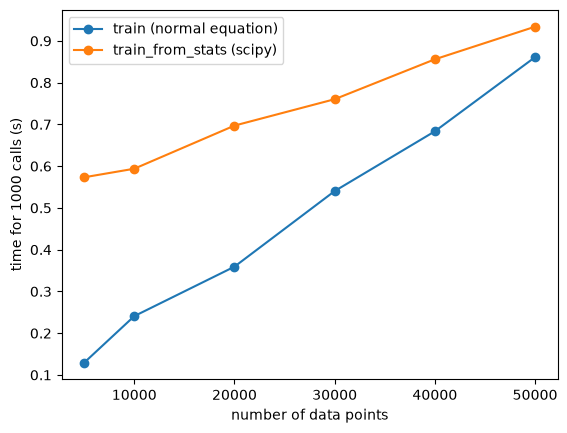

In [11]:
#Optional study: comparing your LLS code and train_from_stats
import io, contextlib

lf = LinearLatentFunction()
sizes = [5000, 10000, 20000, 30000, 40000, 50000]
nb_calls = 1000
time_train, time_stats = [], []

for size in sizes:
    batch = lf.get_batch(size)
    model = LinearModel(size)

    start = time.process_time()
    for _ in range(nb_calls):
        model.train(batch.x_data, batch.y_data)
    time_train.append(time.process_time() - start)
    theta_train = model.theta.copy()

    start = time.process_time()
    with contextlib.redirect_stdout(io.StringIO()):      # hide the prints of train_from_stats
        for _ in range(nb_calls):
            model.train_from_stats(batch.x_data, batch.y_data)
    time_stats.append(time.process_time() - start)
    theta_stats = model.theta.copy()

    print(size, "points | same theta:", np.allclose(theta_train, theta_stats),
          "| train", time_train[-1], "s | train_from_stats", time_stats[-1], "s")

plt.plot(sizes, time_train, marker='o', label="train (normal equation)")
plt.plot(sizes, time_stats, marker='o', label="train_from_stats (scipy)")
plt.xlabel("number of data points")
plt.ylabel("time for 1000 calls (s)")
plt.legend()
plt.show()

## COMMENT Optional study: comparing your LLS code and train_from_stats

Yes, my LLS code gives the same result as `train_from_stats`: the parameters θ are equal up to numerical precision (`np.allclose` is True). My code is faster for all the sizes, and for both functions the time increases with the number of points. The difference is large with 5000 points and becomes small with 50000 points. The reason is that `train_from_stats` has an extra cost: it also computes other statistics (r_value, standard error) that we do not need, while my code only computes the least squares solution. With many points, the time to go through the data is the main cost for both.

# Radial Basis Function Networks

## Coding part 

Let us now code Radial Basis Function Networks (RBFNs). 
We implement several regression techniques with these models: batch least squares, 
gradient descent, and recursive least squares. 
We first define a general purpose RBFN class that encodes the vector of parameters $\theta$, 
the function $\phi(x)$, a function to compute the error of a model and a plotting function.

In [12]:
color_map = ["yellow","brown","orange","green","cyan","pink","red","blue","black","violet"]

class RBFN(Gaussians):
    def __init__(self, nb_features):
        super().__init__(nb_features)
        self.theta = np.zeros(self.nb_features)

    def f(self, x):
        """
        Get the output of the function approximator for a given vector of input variables
        :param x: A vector of input variables of size N
        :return: A vector of function approximator outputs with size the number of x datapoints
        """
        f = np.dot(self.phi_output(x).transpose(), self.theta)
        return f

    def feature(self, x, idx):
        """
        Get the output of the idx^th feature for a given input vector
        This is function f() considering only one feature
        Used mainly for plotting the features

        :param x: A vector of dependent variables of size N
        :param idx: index of the feature

        :return: the value of the feature for x
        """
        phi = self.phi_output(x)
        return phi[idx] * self.theta[idx]

    # -- compute the residuals --#
    def compute_error(self, x_data, y_data):
        """
        Compute the residuals (squared sum of errors) over all the dataset
        :param x_data: the x values of datapoint
        :param y_data: the y values of datapoint

        :return: the residuals of the data given the model
        """
        error = np.linalg.norm(y_data - self.f(x_data))
        return error

    # ------ Plot function -------#
    def plot(self, x_data, y_data, title):
        """
        Given a dataset x_data, y_data, plots the points of the dataset, 
        the feature functions multiplied by their weight parameter 
        and the resulting model of the latent function
        :param x_data: the x values of datapoint
        :param y_data: the y values of datapoint

        :return: nothing
        """
        size = 500
        xs = np.linspace(0.0, 1.0, size)
        z = []
        for i in xs:
            z.append(self.f(np.array([i])))

        z2 = []
        for i in range(self.nb_features):
            temp = []
            for j in xs:
                temp.append(self.feature(np.array([j]), i))
            z2.append(temp)
            plt.plot(xs, z2[i], color=color_map[i%10])
        plt.plot(x_data, y_data, 'o', markersize=3, color='lightgreen')
        plt.plot(xs, z, lw=3, color='red')
        plt.xlabel("x")
        plt.ylabel("y")
        plt.title(title)
        plt.show()

### Batch RBFNs

When applied to RBFNs, there are two perspectives about the batch least squares method.

#### First perspective

The **first perspective** considers that the RBFN is used to project from an input space into a feature space, 
before performing the standard linear least square calculation in this projected space.

Thus, from the batch of data we build the Gram matrix ${\bf G}$, projecting each datapoint $(x_i)_{1 \leq i \leq N}$ 
into its output vector for all the features $(\phi_j({\bf x}_i))_{1 \leq j \leq E}$. 
Then we apply the standard linear least square method, replacing the augmented design matrix $\bar{\bf X}$ with the Gram matrix ${\bf G}$:

$$  \boldsymbol{\theta}^* = ({\bf G}^\intercal{\bf G})^{-1}{{\bf G}}^\intercal{\bf y}.$$

This is the easiest approach to code in python.

In the code of the ```BatchRBFN1``` class below, fill the ```train_ls(self, x_data, y_data)``` function.

In [13]:
class BatchRBFN1(RBFN):
    def __init__(self, nb_features):
        super().__init__(nb_features)

    # ------ batch least squares first perspective) ---------
    def train(self, x_data, y_data):
        
        
        
        G = self.phi_output(x_data).T     
        
        self.theta = np.linalg.pinv(G.T@G)@G.T@y_data      
        #assert False, 'Not implemented yet'


#### Second perspective

In the **second perspective**, we perform the whole calculation from scratch. We want to minimize the following error:
$$\epsilon(\boldsymbol{\theta}) = \frac{1}{2N}\sum_{i=1}^N (y_i - f_{\boldsymbol{\theta}}({\bf x}_i))^2.$$

To get a local minimum over $\boldsymbol{\theta}$ of the function $\epsilon(\boldsymbol{\theta})$, 
we need to solve $\nabla_\boldsymbol{\theta} \epsilon(\boldsymbol{\theta}) = {\bf 0}$.
To compute the gradient, we use $\nabla (g^2) = 2g\nabla g$. Therefore, we have

$$\nabla_\boldsymbol{\theta} \epsilon(\boldsymbol{\theta}) = \frac{1}{N}\sum_{i=1}^N  \left(y_i - f_{\boldsymbol{\theta}}\big( {\bf x}_i\big)\right)\nabla_\boldsymbol{\theta} f_{\boldsymbol{\theta}}({\bf x}_i).$$

Since $f_{\boldsymbol{\theta}}({\bf x}) = \phi({\bf x})^\intercal \boldsymbol{\theta}$, 
we have $\nabla_\boldsymbol{\theta} f_{\boldsymbol{\theta}}({\bf x}_i) = \phi({\bf x}_i)$ and we get

$$\nabla_\boldsymbol{\theta} \epsilon(\boldsymbol{\theta}) = \frac{1}{N}\sum_{i=1}^N  \left(y_i - \phi({\bf x}_i)^\intercal \boldsymbol{\theta}\right)\phi({\bf x}_i)$$

To make the gradient $\nabla_\boldsymbol{\theta} \epsilon(\boldsymbol{\theta}) = {\bf 0}$, we get:

$$\frac{1}{N}\sum_{i=1}^N \left(y_i - \phi({\bf x}_i)^\intercal \boldsymbol{\theta}\right)\phi({\bf x}_i) = 0$$

$$\frac{1}{N}\sum_{i=1}^N \left(\phi({\bf x}_i)y_i - \phi({\bf x}_i) \phi({\bf x}_i)^\intercal \boldsymbol{\theta}\right) = 0$$

$$\left( \sum_{i=1}^N \phi({\bf x}_i) \phi({\bf x}_i)^\intercal \right) \boldsymbol{\theta} = \sum_{i=1}^N \phi({\bf x}_i) y_i.$$

Let us set

$${\bf A} = \left( \sum_{i=1}^N \phi({\bf x}_i) \phi({\bf x}_i)^\intercal \right)$$

and $${\bf b} = \sum_{i=1}^N \phi({\bf x}_i) y_i.$$

We then have ${\bf A} \boldsymbol{\theta} = {\bf b}$.

${\bf A}$ is not necessarily an invertible matrix, and the general solution is obtained as $\boldsymbol{\theta} = A^\sharp b$, 
by using either the ``pseudo-inverse'' $A^\sharp$ ```(np.linalg.pinv(A))``` or using ```theta = np.linalg.solve(A,b)```.

In the ```BatchRBFN2``` class below, fill the code of the ```train(self, x_data, y_data)``` function according to the above perspective.

In [14]:
class BatchRBFN2(RBFN):
    def __init__(self, nb_features):
        super().__init__(nb_features)

    # ------ batch least squares (second perspective) ---------
    def train(self, x_data, y_data):
        
         # 1. A e b partono da zero
        A = np.zeros((self.nb_features, self.nb_features))   # matrice E x E
        b = np.zeros(self.nb_features)                       # vettore di E elementi

        # 2. Un giro per ogni punto
        for i in range(x_data.shape[0]):
            x_i = x_data[i].reshape(1, -1)                
            phi = verti_to_horiz(self.phi_output(x_i))       # phi(x_i): vettore di E valori

            A = A + np.outer(phi, phi)                       #prendi l’A che avevi finora e aggiungici φφᵀ
            b = b + phi * y_data[i]       
        
        self.theta = (np.linalg.pinv(A))@b 
        #assert False, 'Not implemented yet'


Now, run the code below to see if yours works.

theta ls1 : [ 1.09237078  0.75454811  0.73654141  0.80191438  0.75561021  0.83406399
 -0.30085345  0.35262956  0.21870061  0.15797884]
error :  0.4354316826516208
RBFN LS time: 0.002323000000000519


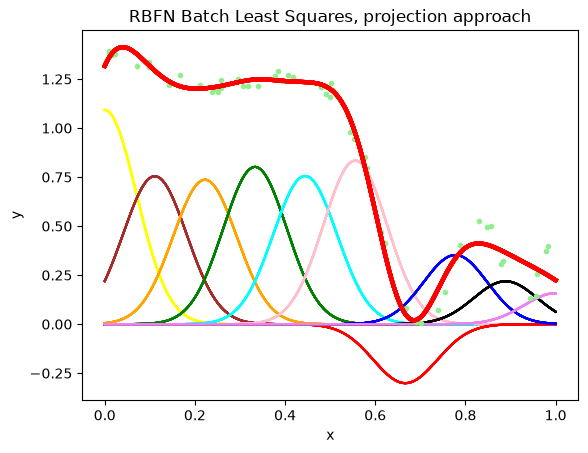

theta ls2 : [ 1.09237078  0.75454811  0.73654141  0.80191438  0.75561021  0.83406399
 -0.30085345  0.35262956  0.21870061  0.15797884]
error :  0.43543168265162063
RBFN LS2 time: 0.0030809999999998894


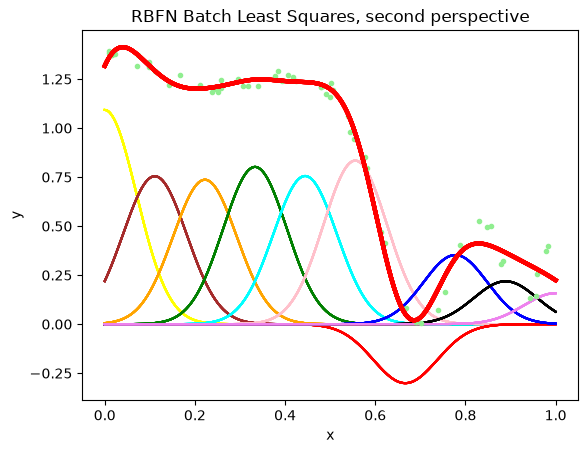

In [15]:
lf = NonLinearLatentFunction()
size = 60
batch = lf.get_batch(size)
model = BatchRBFN1(nb_features=10)

start = time.process_time()
model.train(batch.x_data, batch.y_data)
error = model.compute_error(batch.x_data, batch.y_data)
print("theta ls1 :", model.theta)
print("error : ", error)
print("RBFN LS time:", time.process_time() - start)
model.plot(batch.x_data, batch.y_data, "RBFN Batch Least Squares, projection approach")

model = BatchRBFN2(nb_features=10)
start = time.process_time()
model.train(batch.x_data, batch.y_data)
error = model.compute_error(batch.x_data, batch.y_data)
print("theta ls2 :", model.theta)
print("error : ", error)
print("RBFN LS2 time:", time.process_time() - start)
model.plot(batch.x_data, batch.y_data, "RBFN Batch Least Squares, second perspective")

##  Incremental RBFNs

For this part we define a general purpose IncrRBFN class that we derive below in different subclasses to implement the various algorithms.

In [16]:
class IncrRBFN(RBFN):
    def __init__(self, nb_features):
        super().__init__(nb_features)
        self.theta = np.random.random(self.nb_features)
        print(self.theta)

    def f(self, x, theta=None):
        """
        Get the output of the function approximator for a given vector of input variables 
    
        :param x: A vector of dependent variables of size N
        :param theta: A vector of coefficients to apply to the features. 
        :If left blank the method will default to using the trained thetas in self.theta.
        
        :return: A vector of function approximator outputs with size nb_features
        """
        if not hasattr(theta, "__len__"):
            theta = self.theta
        value = np.dot(self.phi_output(x).transpose(), theta)
        return value

    # -------- this function will be redefined in subclasses -----------------
    def train(self, x, y, alpha):
        raise NotImplementedError

### Gradient Descent

Let the vector $\boldsymbol{\theta}^{(t)}$ be the value of the parameters of the regression model at iteration $t$. 
We observe some new data $({\bf x}^{(t+1)}, y^{(t+1)})$.
The error of the current model on this pair is
$$\epsilon^{(t+1)} = y^{(t+1)} - f_{\boldsymbol{\theta}}( {\bf x}^{(t+1)}).$$

The idea of gradient descent is to slightly modify $\boldsymbol{\theta}$ to decrease $\epsilon^{(t+1)}$.

To do so, we consider the function $\boldsymbol{\theta} \mapsto y^{(t+1)} - f_{\boldsymbol{\theta}}\left( {\bf x}^{(t+1)}\right)$ and compute its gradient in $\boldsymbol{\theta}^{(t+1)}$, which we denote by $\nabla_\boldsymbol{\theta}^{(t+1)}$.

Since we have $f_{\boldsymbol{\theta}}({\bf x}) = \phi({\bf x})^\intercal \boldsymbol{\theta}$, 
we get $\nabla_\boldsymbol{\theta}^{(t+1)} = - \phi({\bf x}^{(t+1)})$.

The gradient of a function is oriented towards the direction of steepest increase. 
This means that it gives the direction in which a small modification of the vector 
of inputs leads to the largest increase of the function output. 
The opposite direction is the one of steepest decrease.

Here, the goal is to decrease $\epsilon^{(t+1)}$ thus $\boldsymbol{\theta}^{(t+1)}$ should be modified 
in the direction defined by $- \nabla_{\boldsymbol{\theta}}^{(t+1)} =  \phi({\bf x}^{(t+1)})$.
The resulting update formula is

\begin{align*}
 \boldsymbol{\theta}^{(t+1)} &= \boldsymbol{\theta}^{(t)} + \alpha \epsilon^{(t+1)} \nabla_{\boldsymbol{\theta}}^{(t+1)} \\
 &= \boldsymbol{\theta}^{(t)} + \alpha (y^{(t+1)} - f_{\boldsymbol{\theta}}( {\bf x}^{(t+1)})) \phi({\bf x}^{(t+1)})^\intercal \\
\end{align*}

where $\alpha > 0$ is a coefficient called the ``learning rate''.

Using $f_{\boldsymbol{\theta}}({\bf x}) = \phi({\bf x})^\intercal \boldsymbol{\theta}$, we can also write it:
$$\boldsymbol{\theta}^{(t+1)} = \boldsymbol{\theta}^{(t)} + \alpha (y^{(t+1)} - \phi({\bf x}^{(t+1)})^\intercal \boldsymbol{\theta}^{(t)}) \phi({\bf x}^{(t+1)})^\intercal.$$

### Relationship to training neural networks

The approach above is at the heart of machine learning techniques used to tune neural networks. 
The error $\epsilon^{(t+1)}$ is called the **loss function**. 
We have seen that we could slightly decrease this error for next time by descending 
the gradient of this loss with respect to the model parameters $\theta$. 
In neural networks libraries such as pytorch or tensorflow, we do the same: 
we compute a loss corresponding to the error made by the model on some data, 
and the library will perform gradient descent with respect to the parameters by computing the derivative for you.

In the GDRBFN class below, fill the `train(self, x, y, alpha)` function.

In [17]:
class GDRBFN(IncrRBFN):
    def __init__(self, nb_features):
        super().__init__(nb_features)

    # -------- gradient descent -----------------
    def train(self, x, y, alpha):
        
        phi = verti_to_horiz(self.phi_output(x))            
        error = y - self.f(x)[0]                           
        self.theta = self.theta + alpha * error * phi

       

And check that it works

[0.5881757  0.05230986 0.96449161 0.11889392 0.93589592 0.27315951
 0.28054517 0.10547257 0.08070643 0.84807684]
error :  0.4554932340983518
RBFN grad descent time: 0.021124999999999616


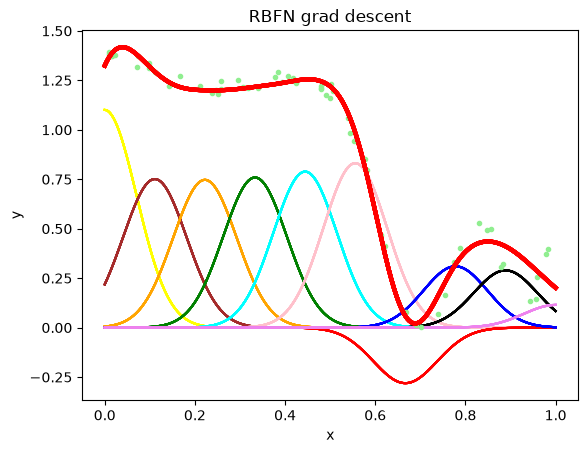

In [18]:
# We use the same batch as before, uncomment if you want to use another batch
# lf = NonLinearLatentFunction()
# size = 500
# batch = lf.get_batch(size)
max_iter = 500
model = GDRBFN(nb_features=10)
start = time.process_time()

for _ in range(max_iter):
    x, y = batch.get_random_sample()
    model.train(x, y, alpha=0.5)

error = model.compute_error(batch.x_data, batch.y_data)
print("error : ", error)
print("RBFN grad descent time:", time.process_time() - start)
model.plot(batch.x_data, batch.y_data, "RBFN grad descent")

### Recursive Least Squares

Recursive Least Squares is the incremental version of the batch Least Squares method.
In this variant, ${\bf A}$ and ${\bf b}$ are recomputed everytime some new data pair is obtained, with the following equations: 

\begin{align*}
{\bf A}^{(t+1)} &= {\bf A}^{(t)} + \phi({\bf x}^{(t+1)}) \phi({\bf x}^{(t+1)})^\intercal,\\
{\bf b}^{(t+1)} &= {\bf b}^{(t)} + \phi({\bf x}^{(t+1)}) y^{(t+1)}.
\end{align*}

The parameters are then computed as $\boldsymbol{\theta}^{(t+1)} = {\bf A}^{(t+1)\sharp} b^{(t+1)}$.
One may also use ```numpy.linalg.solve(A,b)``` as before, but this can fail when ${\bf A}$ is singular.

Another incremental approach avoids the computation of the pseudo-inverse ${\bf A}^{(t+1)\sharp}$ 
by computing this inverse incrementally, using the Sherman-Morrison formula: 

\begin{align*}
  u = v^T &= \phi({\bf x}^{(t)}) \\
{\bf A}^{(t+1)\sharp} &= {\bf A}^{(t)\sharp} - \frac{{\bf A}^{(t)\sharp} uv {\bf A}^{(t)\sharp}}{1 + v {\bf A}^{(t)\sharp} u},\\
{\bf b}^{(t+1)} &= {\bf b}^{(t)} + \phi({\bf x}^{(t)}).\\
\end{align*}

**Remark:** to apply this formula, we must start with a non-zero value for $A^{(0)\sharp}$, e.g. the Identity matrix.

In the RLSRBFN class below, fill the code of the `train(self, x, y)` function. 
The one with the Sherman-Morrisson approach is provided.

In [19]:
class RLSRBFN(IncrRBFN):
    def __init__(self, nb_features):
        super().__init__(nb_features)
        self.a = np.zeros(shape=(self.nb_features, self.nb_features))
        self.b = np.zeros(self.nb_features)
        self.a_inv = np.matrix(np.identity(self.nb_features))
    
    # -------- recursive least squares -----------------
    def train(self, x, y):

        phi = verti_to_horiz(self.phi_output(x))           # phi(x), come in GDRBFN
        self.a =  self.a + np.outer(phi, phi.T)            # aggiungi phi phi^T 
        self.b =  self.b + phi * y                         # aggiungi phi * y
        self.theta = np.linalg.pinv(self.a) @ self.b
       

        
  
    # -------- recursive least squares with Sherman-Morrison -----------------
    def train_rls_sherman_morrison(self, x, y):
        u = self.phi_output(x)
        v = self.phi_output(x).transpose()
        mat = v * self.a_inv * u

        value = mat[0, 0] + 1
        if value == 0: # If it's not invertible
          print("Non invertible matrix")
          return None
        coef = 1.0 / value

        prod = np.dot(u, v)

        tmp_mat = np.dot(self.a_inv, prod) 
        tmp_mat2 = np.dot(tmp_mat, self.a_inv)

        self.a_inv = self.a_inv - coef * tmp_mat2

        tmp_vec = y * verti_to_horiz(self.phi_output(x))
        self.b = self.b + tmp_vec

        # Very surprisingly, we get a [[1 2 3 4]] vec here instead of [1 2 3 4]
        result = np.dot(self.a_inv, self.b)
        # And even more surprisingly we have to write this so that it works
        self.theta = np.array(result)[0]

Finally, run them:

[0.21835134 0.66495015 0.30278657 0.49738424 0.93138833 0.33594912
 0.1847012  0.55794367 0.31475093 0.29973658]
RLS theta [ 1.09340552  0.75498566  0.73701388  0.80137111  0.75590133  0.83387965
 -0.3015315   0.35246606  0.22376063  0.15079268]
error :  0.43559127996037894
RBFN RLS time: 0.5532070000000004


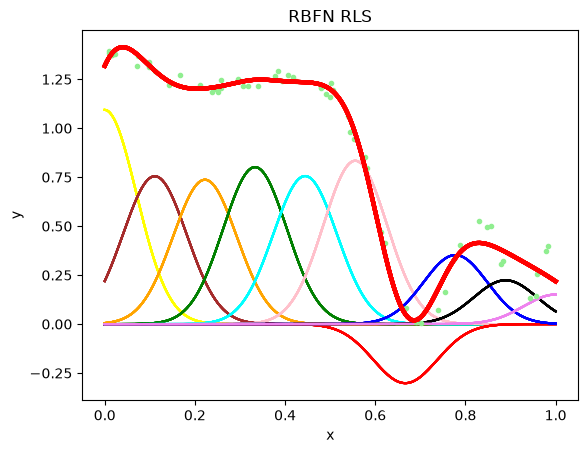

[0.48956177 0.35376818 0.06629772 0.99701602 0.98452632 0.94672451
 0.88663394 0.53941245 0.97128778 0.84376107]
RLS SM theta [ 1.09031951  0.75485575  0.73598848  0.80155966  0.755239    0.83146657
 -0.29329548  0.34846203  0.22500053  0.14772664]
error :  0.43582617354171577
RBFN  Sherman-Morrisson time: 0.36038500000000084


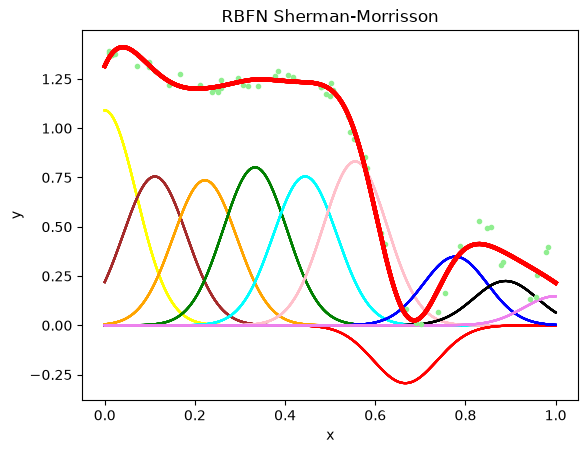

In [20]:
# We use the same batch as before, uncomment if you want to use another batch
# lf = NonLinearLatentFunction()
# size = 500
# batch = lf.get_batch(size)
max_iter = 5000
model = RLSRBFN(nb_features=10)
start = time.process_time()

for _ in range(max_iter):
    x, y = batch.get_random_sample()
    model.train(x, y)

print ("RLS theta", model.theta)
error = model.compute_error(batch.x_data, batch.y_data)
print("error : ", error)
print("RBFN RLS time:", time.process_time() - start)
model.plot(batch.x_data, batch.y_data, "RBFN RLS")

# Need to reinit the model as model.theta must be random again
model = RLSRBFN(nb_features=10)
start = time.process_time()
for _ in range(max_iter):
    x, y = batch.get_random_sample()
    model.train_rls_sherman_morrison(x, y)

print ("RLS SM theta", model.theta)
error = model.compute_error(batch.x_data, batch.y_data)
print("error : ", error)
print("RBFN  Sherman-Morrisson time:", time.process_time() - start)
model.plot(batch.x_data, batch.y_data, "RBFN Sherman-Morrisson")

## Study part: batch RBFNs

 ### Key study: influence of the number of features

Study the evolution of the error as a function of the number of features, from 2 to 60. 
A good idea would be to make a picture with the number of features in the x axis and the residuals in the y axis, 
and then to comment it. Have a look at the model when the number of features is large (e.g. 60). What is happening?

### Optional study: comparing both perspectives

Calling the train functions at least 1000 times, comment on the difference in computation time between the first and the second perspective.

## Study part: incremental RBFNs

### Key study: Incremental versus Batch

By comparing their computation time and error with a growing number of features, 
comment on the main differences between incremental and batch methods with RBFNs. 
What are their main advantages and disadvantages? 
Explain how you would choose between an incremental and a batch method, depending on the context.

### Optional study 1: comparing recursive variants

By varying the number of features, the number of samples and the amount of noise in the data generator, 
compare the different incremental variants (gradient descent and RLS with and without the Sherman-Morrison formula). 
Which is the most precise? The fastest? Using graphical displays where you are varying the above parameters is strongly encouraged. 
To change the amount of noise in the generated data, 
look in the [latent_function.py](https://github.com/osigaud/regressionLabs/blob/main/regression_labs/latent_function.py) file.

### Optional study 2: Studying overfitting

From the same dataset, generate two batches, a training batch on which your model is trained
and a validation batch which is used to determine when incremental regression starts overfitting
Plot training and validation error curves, and conclude on the right number of iterations to avoid overfitting

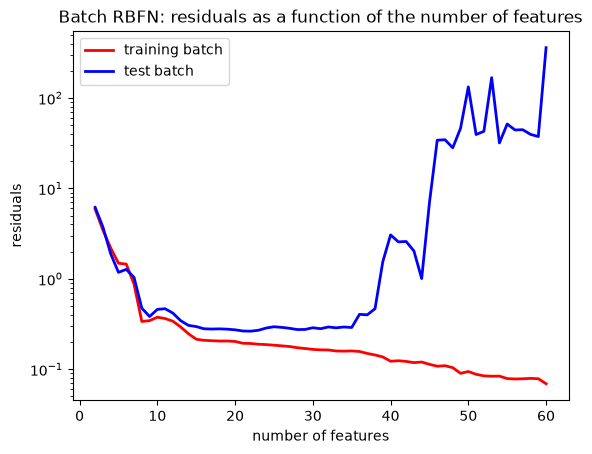

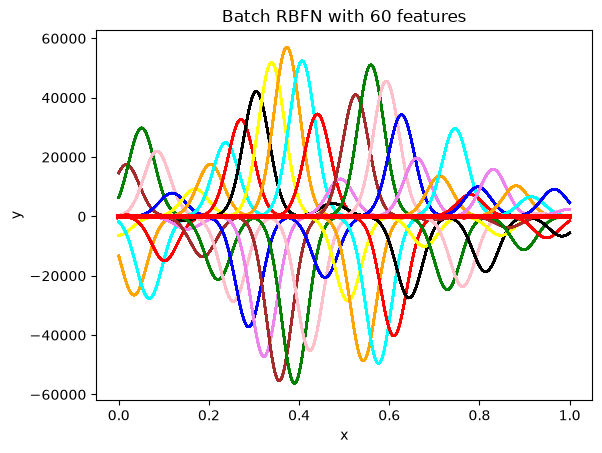

In [21]:
# Key study: influence of the number of features (batch RBFN)

# 1. Generate the data: a training batch and a test batch from the SAME latent function
lf = NonLinearLatentFunction()
size = 60
batch = lf.get_batch(size)          
test_batch = lf.get_batch(size)     

# 2. For each number of features: train a batch RBFN and store the errors
features = range(2, 61)
train_errors = []
test_errors = []
for nb in features:
    model = BatchRBFN1(nb_features=nb)
    model.train(batch.x_data, batch.y_data)
    train_errors.append(model.compute_error(batch.x_data, batch.y_data))
    test_errors.append(model.compute_error(test_batch.x_data, test_batch.y_data))

# 3. Plot the residuals as a function of the number of features
plt.plot(features, train_errors, lw=2, color='red', label="training batch")
plt.plot(features, test_errors, lw=2, color='blue', label="test batch")
plt.yscale("log")                    
plt.xlabel("number of features")
plt.ylabel("residuals")
plt.title("Batch RBFN: residuals as a function of the number of features")
plt.legend()
plt.show()

# 4. Look at the model with many features
model = BatchRBFN1(nb_features=60)
model.train(batch.x_data, batch.y_data)
model.plot(batch.x_data, batch.y_data, "Batch RBFN with 60 features")


## COMMENT:Key study: influence of the number of features

The training residuals decrease quickly up to about 10 features and then keep decreasing slowly. More Gaussians mean more parameters, so the model can fit the training points better and better. The test residuals decrease together with the training ones up to about 10 features (underfitting: with too few Gaussians the model cannot represent the function), then stay almost constant until about 25-30 features. Above about 30 features they increase suddenly, by several orders of magnitude, while the training residuals keep decreasing. With 60 features the weighted Gaussians reach values of the order of 10⁴, much larger than the data (between −0.5 and 1). The Gaussians overlap a lot, so the columns of G are almost collinear and GᵀG is ill-conditioned: the weights θ become huge, with positive and negative values compensating each other to fit the 60 training points, but they do not generalize to new data. This is overfitting: the model learns the noise of the training set. A good choice is therefore a number of features in the flat region of the test residuals, about 10 to 25, where the test error is minimal and the weights remain small.

In [22]:
# Optional study: first perspective versus second perspective

batch = NonLinearLatentFunction().get_batch(200)

model1 = BatchRBFN1(nb_features=30)
start = time.process_time()
for _ in range(1000):
    model1.train(batch.x_data, batch.y_data)
print("first perspective:", time.process_time() - start)

model2 = BatchRBFN2(nb_features=30)
start = time.process_time()
for _ in range(1000):
    model2.train(batch.x_data, batch.y_data)
print("second perspective:", time.process_time() - start)

first perspective: 0.5448810000000002
second perspective: 5.824960000000001


## COMMENT:Optional study 1

The second perspective is about 10 times slower than the first one, even though both give the same solution. The first one uses a single matrix product, which numpy computes very fast. The second one uses a Python `for` loop over all the points, which is much slower. However, the second perspective does not need all the data at once: it only updates A and b one sample at a time, so it is useful when the data arrive sequentially (as in RLS). When all the data are available, the first perspective is better.

[0.11346905 0.54871522 0.84989292 0.58064733 0.9627953 ]
[0.34519803 0.05054829 0.56777489 0.00814665 0.90552473]
[0.01592707 0.00443066 0.16480566 0.90412656 0.16741003 0.00093969
 0.48035665 0.14993606 0.58406407 0.54442242]
[0.05196636 0.56634105 0.62098991 0.62442679 0.03249371 0.67085128
 0.88650577 0.35618452 0.04023865 0.31325891]
[0.80592061 0.2947133  0.19810508 0.96983066 0.41186978 0.71069271
 0.89825566 0.95885245 0.03418603 0.2843517  0.15907975 0.64392425
 0.31736283 0.7616393  0.78305139 0.59268276 0.18001055 0.51176255
 0.00256677 0.0843396 ]
[0.41466651 0.01432281 0.21743295 0.79982137 0.92409818 0.08706225
 0.29624905 0.48424471 0.8507563  0.5119862  0.69275055 0.1210406
 0.70642747 0.1545096  0.24862792 0.72369115 0.7530381  0.33981191
 0.22359251 0.02604857]
[0.78161399 0.27094471 0.23548977 0.01365848 0.25374703 0.3861697
 0.31871955 0.30815191 0.69001181 0.00682397 0.08893682 0.39958425
 0.02498115 0.25845601 0.89669481 0.58855234 0.79883804 0.03483774
 0.73060784

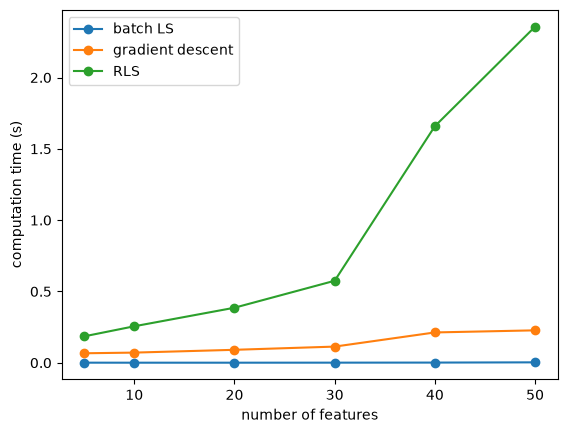

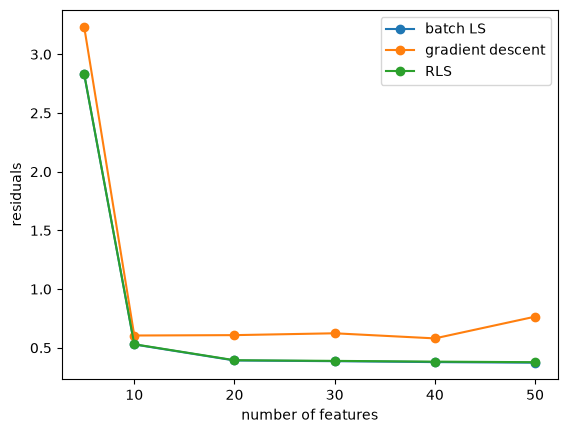

In [23]:
# Key study: incremental versus batch RBFN
batch = NonLinearLatentFunction().get_batch(200)
features = [5, 10, 20, 30, 40, 50]
nb_updates = 2000

time_batch, time_gd, time_rls = [], [], []
err_batch, err_gd, err_rls = [], [], []

for nb in features:
    # batch least squares: all the data at once
    start = time.process_time()
    model = BatchRBFN1(nb_features=nb)
    model.train(batch.x_data, batch.y_data)
    time_batch.append(time.process_time() - start)
    err_batch.append(model.compute_error(batch.x_data, batch.y_data))

    # gradient descent: one random sample at a time
    start = time.process_time()
    model = GDRBFN(nb_features=nb)
    for _ in range(nb_updates):
        x, y = batch.get_random_sample()
        model.train(x, y, alpha=0.5)
    time_gd.append(time.process_time() - start)
    err_gd.append(model.compute_error(batch.x_data, batch.y_data))

    # recursive least squares: one random sample at a time
    start = time.process_time()
    model = RLSRBFN(nb_features=nb)
    for _ in range(nb_updates):
        x, y = batch.get_random_sample()
        model.train(x, y)
    time_rls.append(time.process_time() - start)
    err_rls.append(model.compute_error(batch.x_data, batch.y_data))

# computation time
plt.plot(features, time_batch, marker='o', label="batch LS")
plt.plot(features, time_gd, marker='o', label="gradient descent")
plt.plot(features, time_rls, marker='o', label="RLS")
plt.xlabel("number of features")
plt.ylabel("computation time (s)")
plt.legend()
plt.show()

# residuals
plt.plot(features, err_batch, marker='o', label="batch LS")
plt.plot(features, err_gd, marker='o', label="gradient descent")
plt.plot(features, err_rls, marker='o', label="RLS")
plt.xlabel("number of features")
plt.ylabel("residuals")
plt.legend()
plt.show()

## COMMENT Key study: incremental versus batch RBFN

The batch least squares is by far the fastest method: its computation time is almost zero and does not change with the number of features, because it solves the problem once with all the data. Gradient descent is cheap because each update only involves a vector of size E. RLS is the slowest, and its time grows quickly with the number of features (from a fraction of a second to a few seconds), because at each of the 2000 updates it works with an E×E matrix.

Regarding the error, all the methods have a large error with 5 features (underfitting) and decrease until about 20 features. Batch LS and RLS reach almost the same error (the blue curve is hidden behind the green one). RLS accumulates the same sums as the batch method, one sample at a time: at each new sample it adds a term to A and b and recomputes θ, so after all the samples it solves the same least squares problem (the small difference comes from the random samples, some points being used several times and others never). Gradient descent stays worse because it uses a fixed step size and only 2000 noisy updates, so it does not converge exactly to the least squares solution.

Batch methods are the best choice when all the data are available at once and are not too many: they are fast and give the optimal solution. Their disadvantages are that all the data must be stored and that the computation must be restarted when new data arrive. Incremental methods are preferable when the data arrive one at a time (online learning, for example a robot), when the data are too many to store, or when the environment changes. Gradient descent is cheap but less accurate, whereas RLS is as accurate as the batch method but becomes expensive when the number of features grows.

## Iterative regression with RBFNs

Iterative regression is between batch regression and incremental regression: as in incremental regression, regression is performed iteratively but as in batch regression, we use the full batch of samples at each iteration. Sampling a small subset of the batch (a mini-batch) would correspond to stochastic gradient descent (SGD) whereas standard incremental regression just takes one sample at each iteration.

We do not study iterative regression within this lab, but trying to do it on your own is a valuable exercise.

# Locally Weighted Regression

Another family of models is Locally Weighted Least Squares (LWLS).
The LWLS algorithm uses a weighted sum of $M$ local linear models.
For each local model $\boldsymbol{\theta}_k$, the size of the vector $\boldsymbol{\theta}_k$ 
is the number of dimensions of $\bar{\bf x}$ to take the intercept 
into account (remember that $\bar{\bf x} = ( x_1 \ x_2 \cdots x_d \ 1)^\intercal$ as defined in the provided code 
with the ```bar(x)``` function.
Thus $\dim (\boldsymbol{\theta}_k) = \dim ({\bf x}) +1 = d + 1$.

The model of the global latent function can be written

$$f({\bf x}) = \sum_{k=1}^{M}  \frac{\phi_k({\bf x}). m_{\boldsymbol{\theta}_k}({\bf x})}{\sum_{j=1}^{M} \phi_j({\bf x})},$$

with $m_{\boldsymbol{\theta}_k}({\bf x}) = \bar{\bf x}^\intercal \boldsymbol{\theta}_k $ and where $M$ is the number of models.

Each local model $\boldsymbol{\theta}_k$ is optimized by minimizing the following locally weighted error from $N$ datapoints:

$$\epsilon_k(\boldsymbol{\theta}_k) = \frac{1}{2N}\sum_{i=1}^N \phi_k({\bf x}_i)\left(y_i - m_{\boldsymbol{\theta}_k}({\bf x}_i)\right)^2$$

$$= \frac{1}{2N}\sum_{i=1}^N \phi_k( {\bf x}_i) \left(y_i- (\bar{\bf x}_i)^\intercal .\boldsymbol{\theta}_{i} \right)^2.$$

As with the least squares method, we try to cancel out the gradient, which amounts to solving:

$$-\frac{1}{N}\sum_{i=1}^N \phi_k({\bf x}_i)\bar{\bf x}_i \left(y_i - (\bar{\bf x}_i)^\intercal .\boldsymbol{\theta}_k \right) = 0.$$

Therefore, we pose $\boldsymbol{\theta}_k = {\bf A}^\sharp_k {\bf b}_k$, with: 
$${\bf A}_k = \sum_{i=1}^N \phi_k({\bf x}_i). \bar{\bf x}_i^\intercal. (\bar{\bf x}_i)$$
$${\bf b}_k = \sum_{i=1}^N \phi_k({\bf x}_i). \bar{\bf x}_i^\intercal. y_i.$$

This calculation gives us the parameters $\boldsymbol{\theta}_k$ of each local linear model. 
The global parameter $\boldsymbol{\theta}$ is now a matrix resulting from the concatenation of all local models $\boldsymbol{\theta}_k$.

## Coding part

The code corresponding to the LWR method is available in the ```LWR``` class below. 

**In this code, you have to fill the ```train(self, x_data, y_data)``` function**

In [24]:
class LWR(Gaussians):
    def __init__(self, nb_features):
        super().__init__(nb_features)
        # The first dimension is 2 because we assume the input is one-dimensional
        # So we just have two parameters per receptive field
        self.theta = np.zeros((2, self.nb_features))

    def f(self, x):
        """
        Get the output of the function approximator for a given vector of datapoints
        :param x: a single vector of N datapoints (each datapoint being of dimension d=1)
        :returns: a vector of N function approximator outputs
        """
        weights = self.phi_output(x).T # B x E
        lin_model = bar_design(x) @ self.theta  # B x 2 @ 2 x E = B x E
        weighted_sum = (lin_model * weights).sum(-1) # tensor product
        sum_weights = weights.sum(-1)
        return weighted_sum / sum_weights
      
    def feature(self, x, idx):
        """
         Get the output of the idx^th feature for a given input variable(s)
         :param x: a single or vector of dependent variables with size [d] for which to calculate the features
         :param idx: index of the feature
         :returns: a vector of values
         """
        return np.dot(bar_design(x), self.theta[:, idx])

    # -- compute the residuals --#
    def compute_error(self, x_data, y_data):
      return np.linalg.norm(y_data - self.f(x_data))

    # ----------------------#
    # # Training Algorithm ##
    # ----------------------#

    def train(self, x_data, y_data) -> None:
        """
        Locally weighted least square function
        This code is specific to the 1D case
        :param x_data: a vector of x values
        :param y_data: a vector of y values
        :return: nothing (set the self.theta vector)
        """
        for k in range(self.nb_features):
            A = np.zeros((2, 2))
            b = np.zeros((2, 1))

            nb_points = x_data.shape[0]
            for i in range(nb_points):

                x_i = x_data[i].reshape(1, x_data.shape[1])
                y_i = y_data[i]

                phi = self.phi_output(x_i)

                x_bar = bar_design(x_i)                     
                A = A + phi[k, 0] * (x_bar.T @ x_bar)       
                b = b + phi[k, 0] * x_bar.T * y_i           

            result = np.dot(np.linalg.pinv(A), b)
            for i in range(2):
                self.theta[i, k] = result[i, 0]


    def plot(self, x_data, y_data, title):
        xs = np.linspace(0.0, 1.0, 1000)
        z = []
        for i in xs:
            val = self.f(np.array([[i]]))
            z.append(val)


        plt.plot(x_data, y_data, 'o', markersize=3, color='lightgreen')
        plt.plot(xs, z, lw=2, color='red')
        for i in range(self.nb_features):
            ww = (1.0 - 0.0) / self.nb_features / 2.
            xstmp = np.linspace(self.centers[i] - ww, self.centers[i] + ww, 100)

            z2 = []
            for j in xstmp:
                z2.append(self.feature(np.array([[j]]), i))
            plt.plot(xstmp, z2, lw=2, color='blue', ls='-')
        plt.xlabel("x")
        plt.ylabel("y")
        plt.title(title)
        plt.show()

Once this is done, you can run the code:

LWR time: 0.033822000000000685


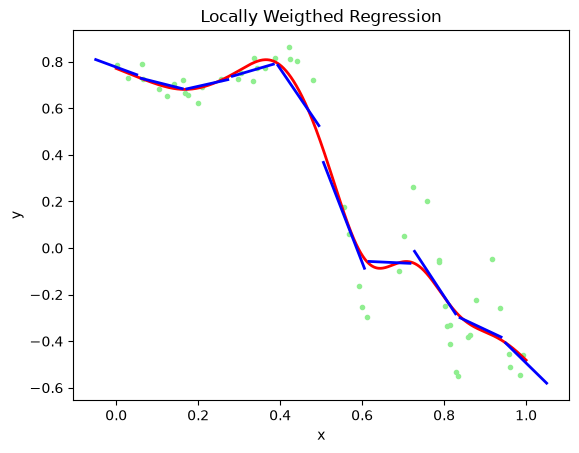

In [25]:
lf = NonLinearLatentFunction()
size = 50
batch = lf.get_batch(size)
model = LWR(nb_features=10)

start = time.process_time()
model.train(batch.x_data, batch.y_data)
print("LWR time:", time.process_time() - start)
model.plot(batch.x_data, batch.y_data, "Locally Weigthed Regression")

## Study part: LWR

### Key study: impact of the number of features

Study the impact of the number of features on the accuracy of LWR: make a drawing where you measure 
the residuals as a function of the number of features.

### Optional study: regions with missing data

Introduce a filter that removes part of the data in some region of the x axis. Study how LWR behaves in regions where data is sparse.
the residuals as a function of the number of features.

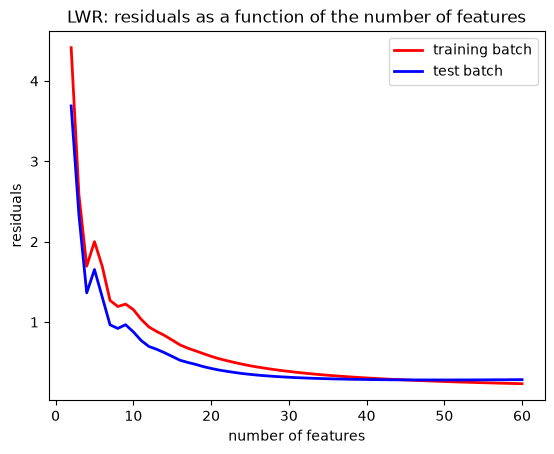

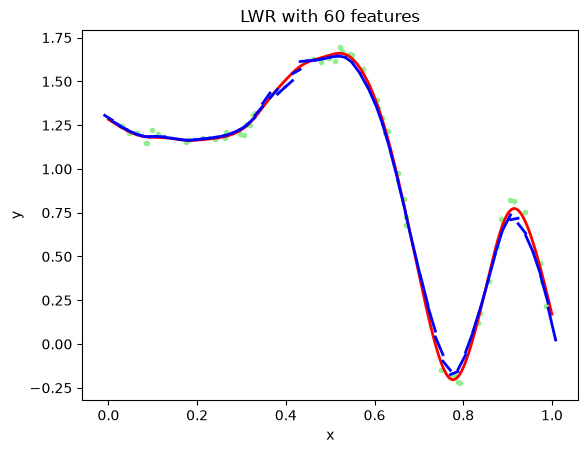

In [26]:
# Key study: impact of the number of features (LWR)

# 1. Data: a training batch and a test batch from the SAME latent function
lf = NonLinearLatentFunction()
size = 60
batch = lf.get_batch(size)
test_batch = lf.get_batch(size)

# 2. For each number of features: train a LWR model and store the residuals
features = range(2, 61)
train_errors = []
test_errors = []
for nb in features:
    model = LWR(nb_features=nb)
    model.train(batch.x_data, batch.y_data)
    train_errors.append(model.compute_error(batch.x_data, batch.y_data))
    test_errors.append(model.compute_error(test_batch.x_data, test_batch.y_data))

# 3. Plot the residuals as a function of the number of features
plt.plot(features, train_errors, lw=2, color='red', label="training batch")
plt.plot(features, test_errors, lw=2, color='blue', label="test batch")
plt.xlabel("number of features")
plt.ylabel("residuals")
plt.title("LWR: residuals as a function of the number of features")
plt.legend()
plt.show()
# 4. Look at the model with many features
model = LWR(nb_features=60)
model.train(batch.x_data, batch.y_data)
model.plot(batch.x_data, batch.y_data, "LWR with 60 features")

## COMMENT:Key study: impact of the number of features

With very few features (about 2 to 8) the residuals are high and irregular: there are only a few local linear models, so each one must cover a large region of the input space, and a straight line cannot follow the curve. From about 10 features on, the residuals decrease regularly on both batches, since each local model only has to be valid in a small neighbourhood of its Gaussian.

The training residuals keep decreasing up to the largest number of features (60). The test residuals also keep decreasing, but more and more slowly after about 30 features, and the gap between the training and the test residuals becomes larger (the beginning of overfitting). However, the test residuals do not increase, and the model with 60 features is a smooth curve which follows the data without oscillations. This is very different from batch RBFNs, where the test residuals explode when the number of features is large: in LWR each local model has only 2 parameters and the output is a weighted average of the local models, so the function stays smooth even when there are many features.

5 features: train 0.928239010094171 test 2.191848196907155


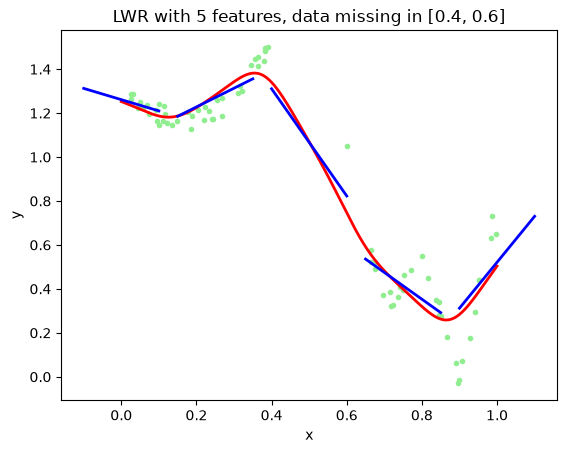

10 features: train 0.7819066435899432 test 1.543552113356107


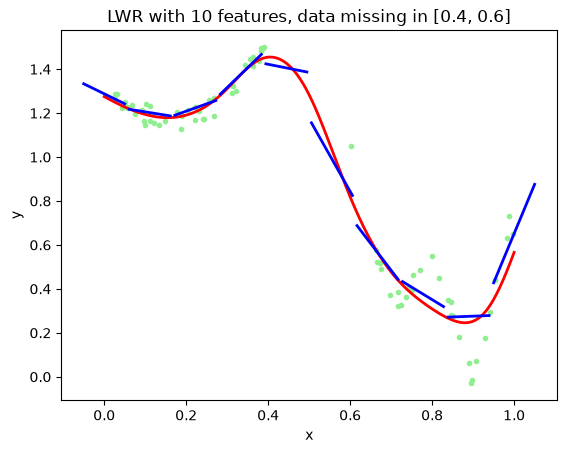

20 features: train 0.5726091514457221 test 1.0553682058457032


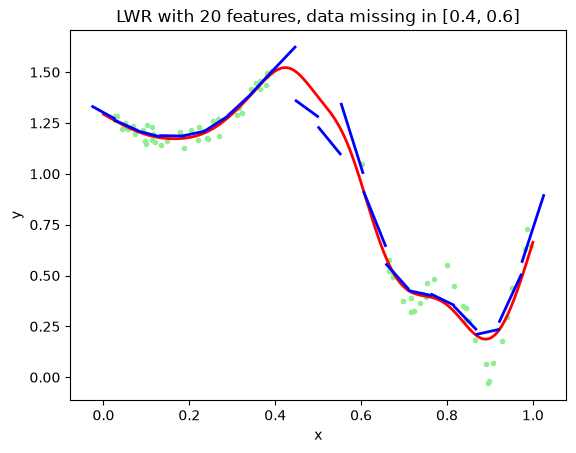

In [27]:
# Optional study: regions with missing data
lf = NonLinearLatentFunction()
batch = lf.get_batch(100)
test_batch = lf.get_batch(100)

# I remove the training points with x between 0.4 and 0.6
x = batch.x_data.ravel()
keep = (x < 0.4) | (x > 0.6)
x_gap, y_gap = batch.x_data[keep], batch.y_data[keep]

for nb in [5, 10, 20]:
    model = LWR(nb_features=nb)
    model.train(x_gap, y_gap)
    print(nb, "features: train", model.compute_error(x_gap, y_gap),
          "test", model.compute_error(test_batch.x_data, test_batch.y_data))
    model.plot(x_gap, y_gap, f"LWR with {nb} features, data missing in [0.4, 0.6]")




In [28]:
# a needed extra part for a check for the interpretation
xt = test_batch.x_data.ravel()
in_gap = (xt >= 0.4) & (xt <= 0.6)
n_in, n_out = in_gap.sum(), (~in_gap).sum()
e_in = model.compute_error(test_batch.x_data[in_gap], test_batch.y_data[in_gap])
e_out = model.compute_error(test_batch.x_data[~in_gap], test_batch.y_data[~in_gap])
print("points inside / outside:", n_in, n_out)
print("error per point inside the gap:", e_in / np.sqrt(n_in))
print("error per point outside the gap:", e_out / np.sqrt(n_out))

points inside / outside: 16 84
error per point inside the gap: 0.18906483326852105
error per point outside the gap: 0.0803173668470394


## COMMENT:Optional study: regions with missing data

I removed the training points with x between 0.4 and 0.6. When the number of features increases, both the training and the test residuals decrease, because the local models follow the data better where there are points. The training and the test batches have a different number of points, so I compare the residuals per point (dividing by the square root of the number of points). Outside the gap the test residuals per point are similar to the training ones, while inside the gap they are higher (about 2 to 3 times), so LWR is less accurate where there is no data. LWR still gives a prediction in the gap, because the Gaussians of the neighbouring local models have a small but non-zero weight there, so it interpolates the data from the two sides. In the plots, the local models inside the gap become less regular when there are more features, because each of them is fitted with very few points. The exact values depend on the random batch, but this behaviour is the same in each run.

# Regression with Neural Networks (in pytorch)

In this part we perform regression with neural networks.
We are using pytorch, which does for you a lot of what you have to code when using gradient descent with RBFNs.

All the code for performing regression is provided, you can focus on the study part.
The study below will focus on different training regimes.

In [29]:
#!pip install torch

import torch as th
from torch import nn
from torch.nn import functional as func
from torch.utils.data import DataLoader
from torch.utils.data import Dataset

We use pytorch Dataset and DataLoader classes to facilitate data processing

In [30]:
class NonLinearRegressionData(Dataset):
    '''
    Custom 'Dataset' object for our regression data.
    Must implement these functions: __init__, __len__, and __getitem__.
    '''

    def __init__(self, x_data, y_data):
        self.x_data = th.from_numpy(x_data).float()
        self.y_data = th.from_numpy(y_data).float()

    def __len__(self):
        return(len(self.x_data))

    def __getitem__(self, idx):
        return(self.x_data[idx], self.y_data[idx])

Now, we define a neural network model.
It has the same $f()$ function as previous models, and the ```compute_error(x,y)``` function is also the same.
But now, the training function just calls ```update(loss)``` and gradient descent is performed using pytorch functions.

In [31]:
##################################################
## set up a multi-layer perceptron with PyTorch
##################################################

class NeuralNetwork(nn.Module):

  def __init__(self, l1, l2, l3, l4, out, learning_rate):
    super(NeuralNetwork, self).__init__()
    self.sigmoid = nn.Sigmoid() # not used in the default version
    self.relu = nn.ReLU()
    self.fc1 = nn.Linear(l1, l2)
    self.fc2 = nn.Linear(l2, l3)
    self.fc3 = nn.Linear(l3, l4)
    self.fc4 = nn.Linear(l4, out)
    self.optimizer = th.optim.Adam(self.parameters(), lr=learning_rate) # Here we could use different optimizers

  def forward(self, x):
      # x is assumed to be a tensor
      hidden1 = self.relu(self.fc1(x))
      hidden2 = self.relu(self.fc2(hidden1))
      hidden3 = self.relu(self.fc3(hidden2))
      output = self.fc4(hidden3)
      return output
  
  def compute_error(self, x_data, y_data):
    """
    Compute the residual error
    :param x_data: the x values of datapoint
    :param y_data: the y values of datapoint
    :return: the total residual error
    """
    x = (th.from_numpy(x_data).float())
    return np.linalg.norm(y_data - self.forward(x).detach().squeeze().numpy())

  def update(self, loss, retain_graph=False) -> None:
    """
    Apply a loss to a network using gradient backpropagation
    :param loss: the applied loss
    :return: nothing
    """
    self.optimizer.zero_grad()
    loss.backward(retain_graph=retain_graph)
    self.optimizer.step()

  def plot(self, x_data, y_data, title):
    """
    Given a dataset x_data, y_data, plots the points of the dataset (in green), 
    and the resulting model of the latent function (in red)
    :param x_data: the x values of datapoint
    :param y_data: the y values of datapoint
    :param title: a title for the figure
    :return: nothing
    """
    
    plt.plot(x_data, y_data, 'o', markersize=3, color='lightgreen')
      
    inputs = th.from_numpy(x_data).float()
    formatted_input = th.reshape(inputs, (len(inputs), 1))
    y_model = model.forward(formatted_input).detach().squeeze().numpy()
      
    plt.plot(x_data, y_model, 'o', markersize=4, color='red')

    size = 500
    xs = np.linspace(0.0, 1.0, size)
    txs = th.from_numpy(xs).float()
    ftxs = th.reshape(txs, (len(txs), 1))
    ys = model.forward(ftxs).detach().squeeze().numpy()
    plt.plot(xs, ys, lw=1, color='pink')

    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(title)
    plt.show()

### General data set-up

We store data into a pytorch dataset

In [32]:
# We use a non-linear batch of size 100
lf = NonLinearLatentFunction()
size = 100
batch = lf.get_batch(size)

# instantiate Dataset object for current training data
train_data = NonLinearRegressionData(batch.x_data, batch.y_data)

### Training loop

In [33]:
def train(max_iter, freq):
  current_loss = 0.0

  # Iterate for a number of training iterations
  for epoch in range(max_iter):
    # Iterate over the DataLoader for training data
    for _, data in enumerate(train_dataloader, 0):
      # Get inputs
      inputs, targets = data
      formatted_input = th.reshape(inputs, (len(inputs), 1))
      outputs = model(formatted_input).squeeze()
      # Compute loss
      loss = func.mse_loss(outputs, targets)
      # Perform optimization
      model.update(loss)
      # Print statistics
      current_loss += loss.item()

    if (epoch + 1) % freq == 0:
      print('Loss after iteration %5d: %.3f' %
            (epoch + 1, current_loss))
      current_loss = 0.0

### Batch, iterative version

We first train the network with a single batch of data.
We perform max_iter iterations to improve the network.

nb iterations 5000
Loss after iteration   250: 16.996
Loss after iteration   500: 6.347
Loss after iteration   750: 5.691
Loss after iteration  1000: 4.601
Loss after iteration  1250: 2.052
Loss after iteration  1500: 0.435
Loss after iteration  1750: 0.269
Loss after iteration  2000: 0.229
Loss after iteration  2250: 0.229
Loss after iteration  2500: 0.229
Loss after iteration  2750: 0.229
Loss after iteration  3000: 0.230
Loss after iteration  3250: 0.229
Loss after iteration  3500: 0.230
Loss after iteration  3750: 0.227
Loss after iteration  4000: 0.228
Loss after iteration  4250: 0.228
Loss after iteration  4500: 0.228
Loss after iteration  4750: 0.228
Loss after iteration  5000: 0.228
Batch training time: 8.965548999999996
Global batch error: 0.29893827401521966


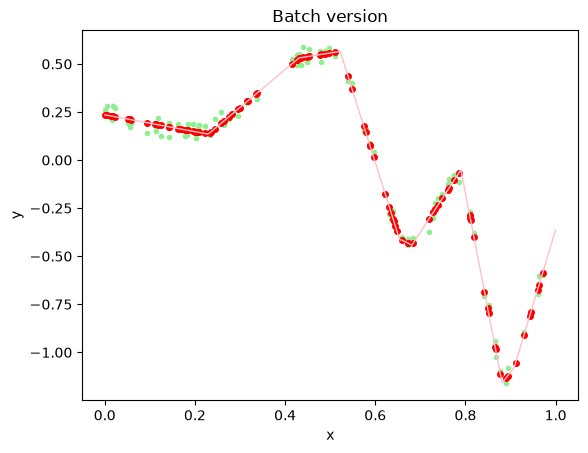

In [34]:
# Instantiate DataLoader
# We get a full size batch and shuffle the data
train_dataloader = DataLoader(train_data, batch_size=size, shuffle=True)

model = NeuralNetwork(1, 10, 10, 10, 1, learning_rate=3e-3)

max_iter = 5000
print("nb iterations", max_iter)

start = time.process_time()
train(max_iter, 250)

print("Batch training time:", time.process_time() - start)
error = model.compute_error(batch.x_data, batch.y_data)
print("Global batch error:", error)
model.plot(batch.x_data, batch.y_data, "Batch version")

### Incremental version using minibatches

For getting minibatches, see the [get_minibatch()](https://github.com/osigaud/regressionLabs/blob/main/regression_labs/batch.py) function.

nb iterations 5000
Loss after iteration   250: 69.978
Loss after iteration   500: 25.259
Loss after iteration   750: 24.475
Loss after iteration  1000: 23.906
Loss after iteration  1250: 23.435
Loss after iteration  1500: 23.076
Loss after iteration  1750: 22.831
Loss after iteration  2000: 22.639
Loss after iteration  2250: 22.463
Loss after iteration  2500: 22.368
Loss after iteration  2750: 22.335
Loss after iteration  3000: 22.319
Loss after iteration  3250: 22.304
Loss after iteration  3500: 22.309
Loss after iteration  3750: 22.298
Loss after iteration  4000: 22.313
Loss after iteration  4250: 22.296
Loss after iteration  4500: 22.300
Loss after iteration  4750: 22.298
Loss after iteration  5000: 22.298
Incremental mini-batch training time: 25.128596
Global batch error: 1.4890461027748128


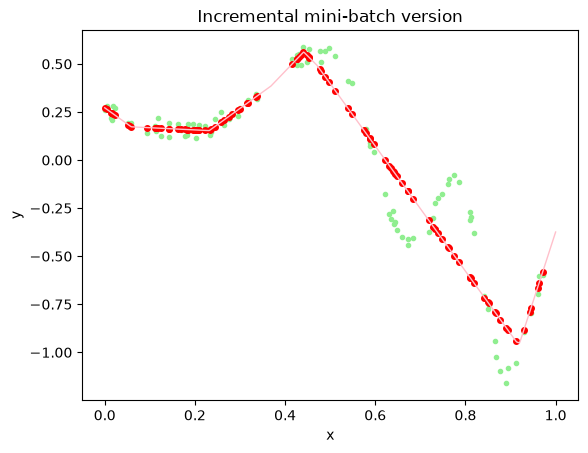

In [35]:
# Instantiate DataLoader
# We get mini_batches of size 25 and shuffle the data
train_dataloader = DataLoader(train_data, batch_size=25, shuffle=True)
model = NeuralNetwork(1, 10, 10, 10, 1, learning_rate=1e-3)

max_iter = 5000
print("nb iterations", max_iter)

start = time.process_time()
train(max_iter, 250)
print("Incremental mini-batch training time:", time.process_time() - start)
error = model.compute_error(batch.x_data, batch.y_data)
print("Global batch error:", error)
model.plot(batch.x_data, batch.y_data, "Incremental mini-batch version")

You can see that the batch version is a special case of the mini-batch version
where the size of the mini-batch is the size of the batch.

## Study part: neural networks

### Key study: comparisons between versions

Play with the dataset size. Once you have properly tuned the variants, study the evolution of the final error
and the training time depending on the size of the minibatch for a given budget of iterations.

Loss after iteration  1000: 151.810
minibatch size 5 | gradient updates 20000 | time 22.049867000000006 | error 0.3590704785419168
Loss after iteration  1000: 64.106
minibatch size 10 | gradient updates 10000 | time 9.865960999999999 | error 0.40352663625389784
Loss after iteration  1000: 96.668
minibatch size 25 | gradient updates 4000 | time 4.318382 | error 0.7932966108508643
Loss after iteration  1000: 77.382
minibatch size 50 | gradient updates 2000 | time 2.3981310000000065 | error 0.943380508234389
Loss after iteration  1000: 45.097
minibatch size 100 | gradient updates 1000 | time 1.4754250000000013 | error 0.9706710526968485


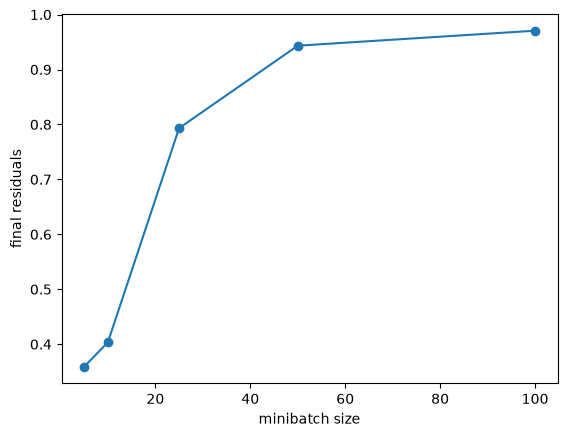

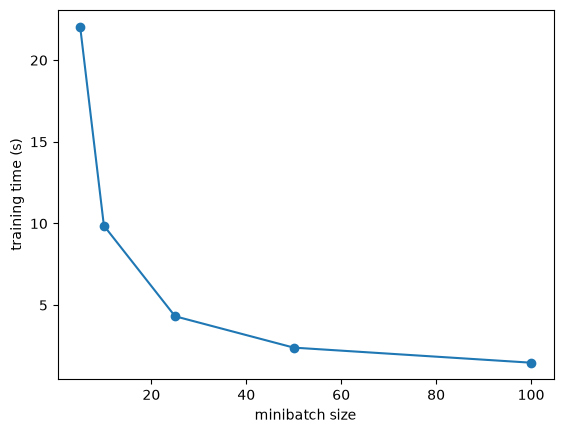

In [36]:
# Key study: impact of the minibatch size (neural network)
batch = NonLinearLatentFunction().get_batch(100)
train_data = NonLinearRegressionData(batch.x_data, batch.y_data)

max_iter = 1000                              # same number of epochs for every run
minibatch_sizes = [5, 10, 25, 50, 100]       # 100 = full batch
final_errors = []
training_times = []

for mb_size in minibatch_sizes:
    train_dataloader = DataLoader(train_data, batch_size=mb_size, shuffle=True)
    model = NeuralNetwork(1, 10, 10, 10, 1, learning_rate=3e-3)

    start = time.process_time()
    train(max_iter, max_iter)
    training_times.append(time.process_time() - start)
    final_errors.append(model.compute_error(batch.x_data, batch.y_data))

    updates = max_iter * int(np.ceil(100 / mb_size))
    print("minibatch size", mb_size, "| gradient updates", updates,
          "| time", training_times[-1], "| error", final_errors[-1])

plt.plot(minibatch_sizes, final_errors, marker='o')
plt.xlabel("minibatch size")
plt.ylabel("final residuals")
plt.show()

plt.plot(minibatch_sizes, training_times, marker='o')
plt.xlabel("minibatch size")
plt.ylabel("training time (s)")
plt.show()


## COMMENT:Key study: comparisons between versions

With the same number of epochs, a smaller minibatch gives more gradient updates (20000 with a minibatch of 5, 1000 with the full batch of 100), so the training time increases a lot when the minibatch is small: it is roughly proportional to the number of updates (about 20 s for a minibatch of 5, about 2 s for the full batch). Regarding the final error, it is in general lower with small minibatches (about 0.5 with a minibatch of 5, about 1 with a minibatch of 25 or larger), because the network makes more updates in the same number of epochs and converges more. The trend is not perfectly regular, since each size was trained only once and the training is random (initialization and shuffling), so the values can change between runs. Small minibatches give more frequent but noisier updates, whereas large minibatches give smoother but fewer updates. There is therefore a trade-off between accuracy and time: for a given budget of epochs, a small minibatch is more accurate but slower, and a larger one is much faster but less accurate.

### Optional study 1: preventing overfitting

Distinguish training, validation and test batches, train the network until the validation loss stops decreasing, 
count the number of training epochs and measure the loss on the test batch.
By running a number of training epochs smaller and larger than the one found with the validation loss approach, 
study if this approach truly prevents overfitting. Showing the training loss and validation loss curves is higly recommended.

### Optional study 2: impact of the network architecture

Vary the activation functions, the number of layers and the number of neurons per layer and study the impact on regression error.

# Global study part: comparing the families of methods

### Optional study 1: Batch RBFNs versus LWR

By using the same batches of data and tuning your models depending on these batches, compare the performance
and training time of batch RBFNs and LWR under various training regimes. Change the amount of noise, the quantity of data,
or study the impact of missing data.

### Optional study 2: Incremental RBFNs versus neural networks

By using the same batches of data and tuning your models depending on these batches, compare the performance
and training time of incremental RBFNs and neural networks under various training regimes.
 Change the amount of noise, the quantity of data, or study the impact of missing data.

best epoch (validation): 1997
epoch 499 | train 0.15376870979874555 | validation 0.2973281455356278 | test 0.31264155666901094
epoch 998 | train 0.04283325691648626 | validation 0.11223347300731172 | test 0.11341361965653451
epoch 1997 | train 0.04216007817081622 | validation 0.05478982322464182 | test 0.05873957144583587
epoch 3994 | train 0.04007550579980478 | validation 0.1236766404880915 | test 0.12225428547825834
epoch 4999 | train 0.03826146674002738 | validation 0.16843231274254558 | test 0.15625637483675692


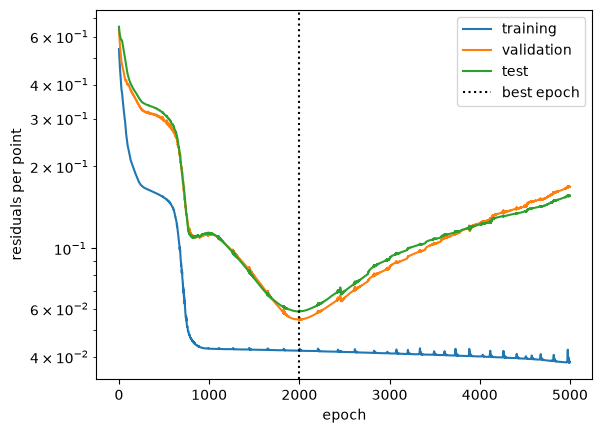

In [37]:
# Optional study: preventing overfitting (neural network)
np.random.seed(1)
th.manual_seed(1)
lf = NonLinearLatentFunction()
train_batch = lf.get_batch(20)
val_batch = lf.get_batch(100)
test_batch = lf.get_batch(100)

train_data = NonLinearRegressionData(train_batch.x_data, train_batch.y_data)
train_dataloader = DataLoader(train_data, batch_size=20, shuffle=True)
model = NeuralNetwork(1, 10, 10, 10, 1, learning_rate=3e-3)

# residuals per point, so that batches of different size can be compared
def error(batch):
    return model.compute_error(batch.x_data, batch.y_data) / np.sqrt(len(batch.x_data))

max_epochs = 5000
train_errors, val_errors, test_errors = [], [], []
for epoch in range(max_epochs):
    for inputs, targets in train_dataloader:
        outputs = model(th.reshape(inputs, (len(inputs), 1))).squeeze()
        model.update(func.mse_loss(outputs, targets))
    train_errors.append(error(train_batch))
    val_errors.append(error(val_batch))
    test_errors.append(error(test_batch))

# best epoch = minimum of the validation error (early stopping)
best_epoch = int(np.argmin(val_errors))
print("best epoch (validation):", best_epoch)
for ep in [best_epoch // 4, best_epoch // 2, best_epoch, min(2 * best_epoch, max_epochs - 1), max_epochs - 1]:
    print("epoch", ep, "| train", train_errors[ep], "| validation", val_errors[ep], "| test", test_errors[ep])

plt.plot(train_errors, label="training")
plt.plot(val_errors, label="validation")
plt.plot(test_errors, label="test")
plt.axvline(best_epoch, ls=':', color='black', label="best epoch")
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("residuals per point")
plt.legend()
plt.show()

## COMMENT:Optional study: preventing overfitting (neural network)

The training residuals decrease quickly and then keep decreasing slowly, whereas the validation and test residuals decrease only until the best epoch (the one with the lowest validation residuals) and then increase: this is overfitting, because the network has many parameters and only 20 training points. With much fewer epochs than the best one the network underfits and all the residuals are higher. At the best epoch the test residuals are about the lowest, whereas with more epochs they are larger, so stopping when the validation residuals are minimal truly prevents overfitting. The test points were not used to choose the epoch, and the validation and test curves are very close. This is a single run on a small training batch, so the exact values depend on the seed.

NOTE: The network is trained for 5000 epochs and the best epoch is chosen afterwards as the one with the lowest validation residuals, which is equivalent to stopping the training at that epoch

In [38]:
# Optional study: impact of the network architecture
class FlexibleNN(NeuralNetwork):
    def __init__(self, hidden, activation):
        super().__init__(1, 1, 1, 1, 1, 3e-3)
        layers, n_in = [], 1
        for h in hidden:
            layers += [nn.Linear(n_in, h), activation()]
            n_in = h
        self.net = nn.Sequential(*layers, nn.Linear(n_in, 1))
        self.optimizer = th.optim.Adam(self.net.parameters(), lr=3e-3)

    def forward(self, x):
        return self.net(x)

lf = NonLinearLatentFunction()
batch = lf.get_batch(100)
test_batch = lf.get_batch(100)
train_data = NonLinearRegressionData(batch.x_data, batch.y_data)
train_dataloader = DataLoader(train_data, batch_size=50, shuffle=True)

configs = [
    ("ReLU, 3 layers x 10", [10, 10, 10], nn.ReLU),
    ("Tanh, 3 layers x 10", [10, 10, 10], nn.Tanh),
    ("Sigmoid, 3 layers x 10", [10, 10, 10], nn.Sigmoid),
    ("ReLU, 1 layer x 10", [10], nn.ReLU),
    ("ReLU, 5 layers x 10", [10] * 5, nn.ReLU),
    ("ReLU, 3 layers x 3", [3, 3, 3], nn.ReLU),
    ("ReLU, 3 layers x 30", [30, 30, 30], nn.ReLU),
]

for name, hidden, activation in configs:
    model = FlexibleNN(hidden, activation)
    train(1000, 1000)
    print(name, "| train", model.compute_error(batch.x_data, batch.y_data),
          "| test", model.compute_error(test_batch.x_data, test_batch.y_data))

Loss after iteration  1000: 139.967
ReLU, 3 layers x 10 | train 1.9965265031564698 | test 2.3271244898969883
Loss after iteration  1000: 140.679
Tanh, 3 layers x 10 | train 1.6978941204760885 | test 1.936806253142332
Loss after iteration  1000: 123.540
Sigmoid, 3 layers x 10 | train 2.0856451533705784 | test 2.398524199393831
Loss after iteration  1000: 213.873
ReLU, 1 layer x 10 | train 2.1005749511134573 | test 2.4207321654209397
Loss after iteration  1000: 133.625
ReLU, 5 layers x 10 | train 2.011558630411638 | test 2.3356313970845197
Loss after iteration  1000: 289.207
ReLU, 3 layers x 3 | train 2.291282189054244 | test 2.620819026638705
Loss after iteration  1000: 113.766
ReLU, 3 layers x 30 | train 2.0057356519754554 | test 2.316003400048641


## COMMENT:Optional study: impact of the network architecture

I changed one thing at a time with respect to the default network (ReLU, 3 layers of 10 neurons), with the same training budget (1000 epochs, minibatch of 50). The number of neurons per layer has the clearest effect: 
with 30 neurons per layer the residuals are much lower (about 0.3 on the test batch) than with 10 neurons (about 0.75). The number of layers (1, 3 or 5) and the activation function (ReLU, Tanh, Sigmoid) have little effect
here: all these networks have similar residuals (about 0.7 to 0.8), and the small differences between them are probably within the noise of a single training run. Sigmoid is slightly worse, which can be explained by its
slower training because of the small gradients of the saturated sigmoid. The training and the test residuals are close, so there is no overfitting with these networks and 100 points. These results are for a fixed number of
epochs: the small or deep networks may be slower to train, and could reach a lower error with more epochs, so this study compares how fast the networks learn and not only their capacity. Each configuration was trained only
once, so the values can change between runs.

20 points | test error: RBFN 2301.019760022156 LWR 1.446661266367978 | time: RBFN 0.0012049999999987904 LWR 0.02509200000000078
50 points | test error: RBFN 0.6878193658004467 LWR 0.8879657734723064 | time: RBFN 0.000602999999983922 LWR 0.057762999999994236
100 points | test error: RBFN 0.5425884252241319 LWR 0.6849319325808643 | time: RBFN 0.00028399999999351166 LWR 0.1017180000000053
200 points | test error: RBFN 0.5385756277299177 LWR 0.7544676131829583 | time: RBFN 0.0006380000000092423 LWR 0.2004959999999869
400 points | test error: RBFN 0.5253831337464587 LWR 0.8395592685490628 | time: RBFN 0.000821000000001959 LWR 0.38010499999998615


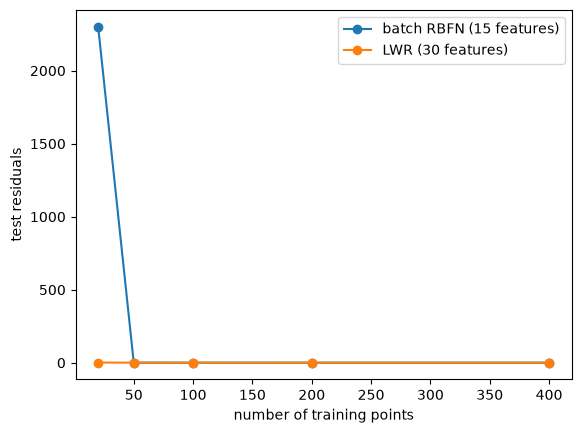

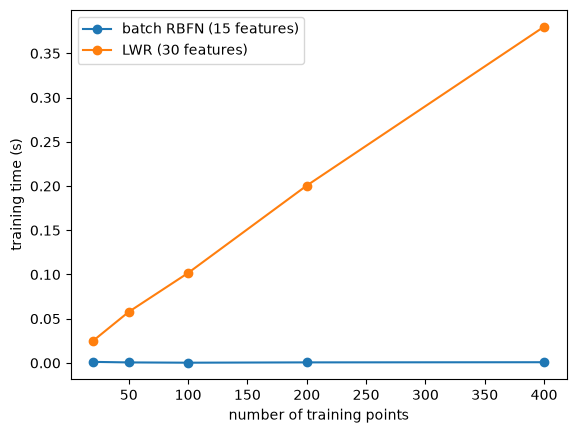

In [39]:
# Optional study: batch RBFN versus LWR, impact of the quantity of data
lf = NonLinearLatentFunction()
test_batch = lf.get_batch(200)
sizes = [20, 50, 100, 200, 400]

err_rbfn, err_lwr, time_rbfn, time_lwr = [], [], [], []
for size in sizes:
    batch = lf.get_batch(size)

    start = time.process_time()
    model = BatchRBFN1(nb_features=15)
    model.train(batch.x_data, batch.y_data)
    time_rbfn.append(time.process_time() - start)
    err_rbfn.append(model.compute_error(test_batch.x_data, test_batch.y_data))

    start = time.process_time()
    model = LWR(nb_features=30)
    model.train(batch.x_data, batch.y_data)
    time_lwr.append(time.process_time() - start)
    err_lwr.append(model.compute_error(test_batch.x_data, test_batch.y_data))

    print(size, "points | test error: RBFN", err_rbfn[-1], "LWR", err_lwr[-1],
          "| time: RBFN", time_rbfn[-1], "LWR", time_lwr[-1])

plt.plot(sizes, err_rbfn, marker='o', label="batch RBFN (15 features)")
plt.plot(sizes, err_lwr, marker='o', label="LWR (30 features)")
plt.xlabel("number of training points")
plt.ylabel("test residuals")
plt.legend()
plt.show()

plt.plot(sizes, time_rbfn, marker='o', label="batch RBFN (15 features)")
plt.plot(sizes, time_lwr, marker='o', label="LWR (30 features)")
plt.xlabel("number of training points")
plt.ylabel("training time (s)")
plt.legend()
plt.show()

## COMMENT:Optional study: Batch RBFNs versus LWR


I trained the two models on the same data, from 20 to 400 points, and I compared the test residuals and the training time. With only 20 points the batch RBFN is much worse than LWR: it has 15 parameters and only 20 points, so it overfits and the test residuals are huge. LWR stays reasonable because each local model has only 2 parameters. With 50 points or more the batch RBFN has lower test residuals than LWR in all the cases I tried, so it is the more accurate model when there are enough data. About the time, the batch RBFN is very fast, because it solves one least squares problem, while LWR is much slower and its time grows with the number of points, because it solves one problem for each feature. So the batch RBFN is better when there are enough data (more accurate and faster), and LWR is safer when there are few data, but it is slower.